In [1]:
import json
import pandas as pd
import numpy as np
import seaborn as sns
import warnings
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, chi2_contingency
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import roc_curve, auc
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline

from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.feature_selection import RFECV

In [2]:
df = pd.read_json('train.jsonl', lines = True)

df.head()

,battle_id,p1_team_details,p2_lead_details,battle_timeline,player_won
0,0,"[{'name': 'tyranitar', 'level': 100, 'types': ...","{'name': 'forretress', 'level': 100, 'types': ...","[{'turn': 1, 'p1_pokemon_state': {'name': 'tyr...",0
1,1,"[{'name': 'raikou', 'level': 100, 'types': ['e...","{'name': 'raikou', 'level': 100, 'types': ['el...","[{'turn': 1, 'p1_pokemon_state': {'name': 'rai...",0
2,2,"[{'name': 'raikou', 'level': 100, 'types': ['e...","{'name': 'exeggutor', 'level': 100, 'types': [...","[{'turn': 1, 'p1_pokemon_state': {'name': 'her...",0
3,3,"[{'name': 'zapdos', 'level': 100, 'types': ['e...","{'name': 'cloyster', 'level': 100, 'types': ['...","[{'turn': 1, 'p1_pokemon_state': {'name': 'zap...",0
4,4,"[{'name': 'nidoking', 'level': 100, 'types': [...","{'name': 'zapdos', 'level': 100, 'types': ['el...","[{'turn': 1, 'p1_pokemon_state': {'name': 'nid...",0


In [3]:
# Step 1: Load the Battle Logs (train.jsonl)
# Each line in JSON file is a separate battle record
data = []
with open('train.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        data.append(json.loads(line))

print(f"Loaded {len(data)} battles from train.jsonl")

# Step 2: Load Type Chart and create Lookup Dictionary
type_chart_df = pd.read_csv('type_chart_gen2.csv')

# Create a dictionary for 0(1) time complexity lookups during feature extraction
# Key: (attacking_type, defending_type); Value: damage multiplier (e. g., 2.0, 0.5, 0.0)

type_lookup = {}
for _, row in type_chart_df.iterrows():
    atk = str(row['attacking_type']).lower()
    dfnd = str(row['defending_type']).lower()
    type_lookup[(atk, dfnd)] = row['multiplier']

print(f"Loaded {len(type_lookup)} type match-up rules from type_chart_gen2.csv")


Loaded 10000 battles from train.jsonl
Loaded 110 type match-up rules from type_chart_gen2.csv


In [4]:
# Step 3 & 4: Extracting Data from JSON
def get_poke_matchup(atk_types, def_types):
    if not atk_types or not def_types: return 1.0
    best_mult = 1.0
    for a_type in atk_types:
        if not a_type: continue
        mult = 1.0
        for d_type in def_types:
            if d_type: mult *= type_lookup.get((a_type.lower(), d_type.lower()), 1.0)
        best_mult = max(best_mult, mult)
    return best_mult

def extract_pro_features(battle):
    features = {'battle_id': battle.get('battle_id')}
    if 'player_won' in battle: features['player_won'] = battle.get('player_won')

    p1_team = battle.get('p1_team_details', [])
    p2_lead = battle.get('p2_lead_details', {})
    timeline = battle.get('battle_timeline', [])

    p1_lead_name = timeline[0].get('p1_pokemon_state', {}).get('name') if timeline else None
    p1_lead = next((p for p in p1_team if p.get('name') == p1_lead_name), p1_team[0] if p1_team else {})

    p2_lead_spe = p2_lead.get('base_spe', 0)
    features['lead_spe_diff'] = p1_lead.get('base_spe', 0) - p2_lead_spe
    features['lead_diff_atk'] = p1_lead.get('base_atk', 0) - p2_lead.get('base_atk', 0)

    p1_switches, p2_switches = 0, 0
    p1_seen_hp, p2_seen_hp = {}, {}
    p1_statuses, p2_statuses = set(), set()
    prev_p1, prev_p2 = None, None

    for turn in timeline:
        s1, s2 = turn.get('p1_pokemon_state', {}) or {}, turn.get('p2_pokemon_state', {}) or {}
        n1, n2 = s1.get('name'), s2.get('name')

        if prev_p1 and n1 and n1 != prev_p1: p1_switches += 1
        if prev_p2 and n2 and n2 != prev_p2: p2_switches += 1
        prev_p1, prev_p2 = n1, n2

        for name, state, hp_dict, status_set in [(n1, s1, p1_seen_hp, p1_statuses), (n2, s2, p2_seen_hp, p2_statuses)]:
            if not name: continue
            hp_val = state.get('hp_pct', state.get('hp', state.get('current_hp', state.get('health', None))))
            if isinstance(hp_val, (int, float)): hp_dict[name] = hp_val

            status = state.get('status')
            if status and str(status).lower() not in ('none', 'null', 'healthy', ''):
                status_set.add((name, str(status).lower()))
                if str(status).lower() in ('fnt', 'fainted', 'dead'): hp_dict[name] = 0.0

    features['switch_diff'] = p1_switches - p2_switches
    features['revealed_diff'] = len(p1_seen_hp) - len(p2_seen_hp)

    features['p1_avg_last_hp'] = np.mean(list(p1_seen_hp.values())) if p1_seen_hp else 0.0
    features['p2_avg_last_hp'] = np.mean(list(p2_seen_hp.values())) if p2_seen_hp else 0.0
    features['avg_hp_diff'] = features['p1_avg_last_hp'] - features['p2_avg_last_hp']

    features['status_diff'] = len(p2_statuses) - len(p1_statuses)

    if timeline:
        last_s1, last_s2 = timeline[-1].get('p1_pokemon_state', {}) or {}, timeline[-1].get('p2_pokemon_state', {}) or {}
        hp1 = last_s1.get('hp_pct', last_s1.get('hp', last_s1.get('current_hp', 0)))
        hp2 = last_s2.get('hp_pct', last_s2.get('hp', last_s2.get('current_hp', 0)))
        if isinstance(hp1, (int, float)) and isinstance(hp2, (int, float)):
            features['last_turn_hp_diff'] = hp1 - hp2

    return features

# Step 5: Build final df_pro
print("Extracting features from JSON logs...")
df_pro = pd.DataFrame([extract_pro_features(b) for b in data])
print(f"Dataset successfully built! Shape: {df_pro.shape}")



Extracting features from JSON logs...
Dataset successfully built! Shape: (10000, 11)


Starting Exploratory Data Analysis (EDA)...


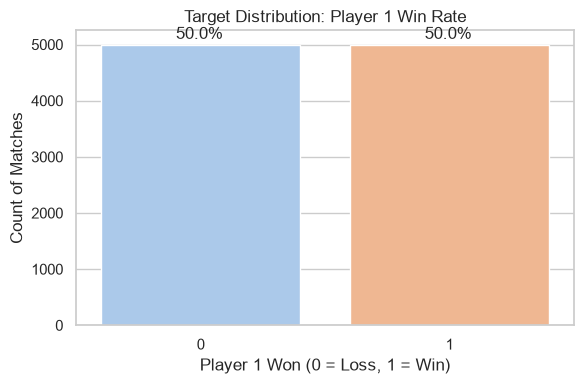

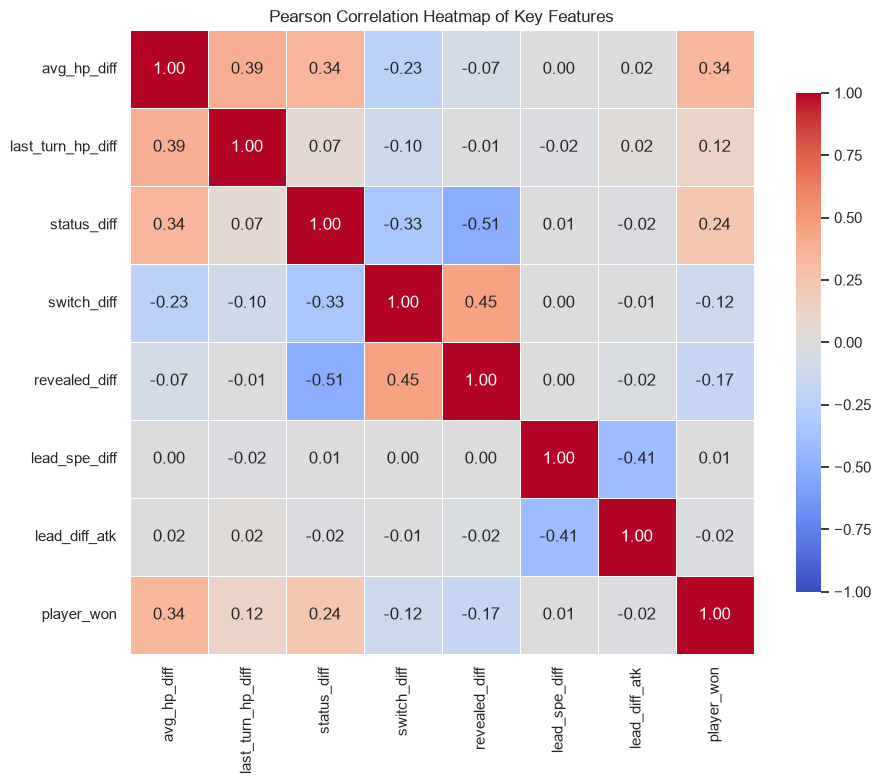

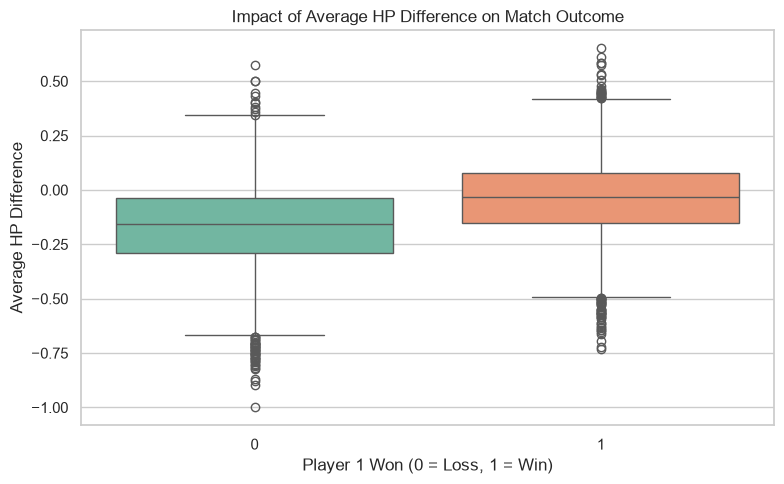

In [5]:
# Set a clean visual style for the plots
sns.set_theme(style="whitegrid")
print("Starting Exploratory Data Analysis (EDA)...")

# EDA 1: Target variable balance
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_pro, x='player_won', palette='pastel', hue='player_won', legend=False)
plt.title('Target Distribution: Player 1 Win Rate')
plt.xlabel('Player 1 Won (0 = Loss, 1 = Win)')
plt.ylabel('Count of Matches')

total = len(df_pro)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.1
    y = p.get_height() + (total * 0.01)
    ax.annotate(percentage, (x, y), size=12)

plt.tight_layout()
plt.show()

# EDA: 2 Correlation Heatmap
# Select key tactical features to check for multicollinearity
eda_cols = [
    'avg_hp_diff', 'last_turn_hp_diff', 'status_diff',
    'switch_diff', 'revealed_diff', 'lead_spe_diff',
    'lead_diff_atk', 'player_won'
]

corr_df = df_pro[eda_cols].dropna()

plt.figure(figsize=(10, 8))
corr = corr_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title('Pearson Correlation Heatmap of Key Features')
plt.tight_layout()
plt.show()

# EDA 3: Boxplot
# Visualize how average HP difference separates the classes
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_pro, x='player_won', y='avg_hp_diff', palette='Set2', hue='player_won', legend=False)
plt.title('Impact of Average HP Difference on Match Outcome')
plt.xlabel('Player 1 Won (0 = Loss, 1 = Win)')
plt.ylabel('Average HP Difference')
plt.tight_layout()
plt.show()


In [6]:
# Step 6: Statistical feature selection (Filter method)
def stat_feature_selection(df, target_col='player_won', alpha=0.05):
    significant_features = []

    # Split the dataset by target class for comparison
    won_mask = df[target_col] == 1
    df_won = df[won_mask]
    df_lost = df[~won_mask]

    print(f"{'Feature':<25} | {'Test Used':<15} | {'p-value':<12} | {'Action'}")
    print("-" * 75)

    for col in df.columns:
        if col in [target_col, 'battle_id']:
            continue

            # Treat features with few unique values as categorical (Chi-Square)
        if df[col].nunique() <= 10:
            contingency_table = pd.crosstab(df[col], df[target_col])
            chi2, p_val, _, _ = chi2_contingency(contingency_table)
            test_name = "Chi-Square"
        # Continuous features get Mann-Whitney U
        else:
            stat, p_val = mannwhitneyu(df_won[col], df_lost[col], alternative='two-sided')
            test_name = "Mann-Whitney"

        if p_val < alpha:
            significant_features.append(col)
            print(f"{col:<25} | {test_name:<15} | {p_val:<12.5e} | [RETAIN]")
        else:
            print(f"{col:<25} | {test_name:<15} | {p_val:<12.5f} | [DROP - Noise]")

    return significant_features

print("Running Statistical Hypothesis Testing on Features...\n")
good_features = stat_feature_selection(df_pro)

# STep 7: Create Cleaned Dataset for Modeling
final_cols = good_features + ['player_won']
df_clean = df_pro[final_cols].copy()

X = df_clean.drop(columns=['player_won'])
y = df_clean['player_won']

print(f"\nOriginal features: {df_pro.shape[1] - 2}")
print(f"Cleaned features:  {X.shape[1]}")



Running Statistical Hypothesis Testing on Features...

Feature                   | Test Used       | p-value      | Action
---------------------------------------------------------------------------
lead_spe_diff             | Mann-Whitney    | 0.37062      | [DROP - Noise]
lead_diff_atk             | Mann-Whitney    | 3.33908e-02  | [RETAIN]
switch_diff               | Mann-Whitney    | 1.67908e-35  | [RETAIN]
revealed_diff             | Mann-Whitney    | 8.05693e-59  | [RETAIN]
p1_avg_last_hp            | Mann-Whitney    | 6.13539e-86  | [RETAIN]
p2_avg_last_hp            | Mann-Whitney    | 3.21843e-26  | [RETAIN]
avg_hp_diff               | Mann-Whitney    | 6.51322e-243 | [RETAIN]
status_diff               | Mann-Whitney    | 4.34040e-123 | [RETAIN]
last_turn_hp_diff         | Mann-Whitney    | 3.56226e-25  | [RETAIN]

Original features: 9
Cleaned features:  8


Initializing LightGBM and Randomized Search...

Best ROC-AUC Score: 0.7173
Best Parameters:    {'subsample': 1.0, 'num_leaves': 15, 'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 0.9}



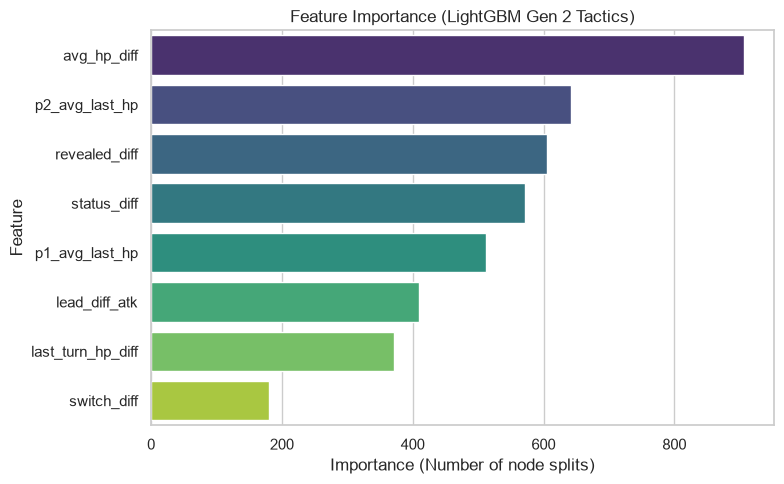

Calculating Cross-Validated ROC Curve...


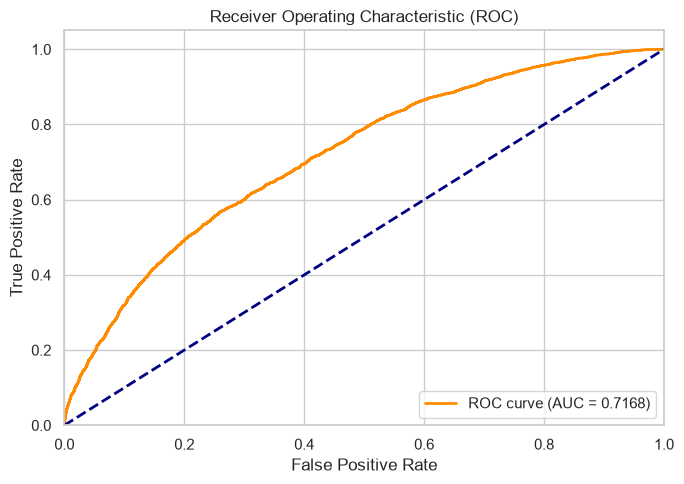

In [7]:
# STEP 8: Model Tuning (LightGBM + RandomizedSearchCV)
print("Initializing LightGBM and Randomized Search...")

# 5-fold cross-validation for robust evaluation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define hyperparameter space
param_dist = {
    'num_leaves': [15, 31, 63],
    'max_depth': [4, 6, 8, 10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

# Initialize LightGBM (verbose=-1 suppresses internal warnings)
lgbm = LGBMClassifier(random_state=42, verbose=-1)

# Run fast randomized search (20 iterations)
random_search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_dist,
    n_iter=20,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42
)

random_search.fit(X, y)

print(f"\nBest ROC-AUC Score: {random_search.best_score_:.4f}")
print(f"Best Parameters:    {random_search.best_params_}\n")

# Step 9: Visualization (Feature Importance & ROC Curve)

best_model = random_search.best_estimator_

# Plot 1: Feature Importance
fi_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=fi_df, x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title('Feature Importance (LightGBM Gen 2 Tactics)')
plt.xlabel('Importance (Number of node splits)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Plot 2: ROC Curve
print("Calculating Cross-Validated ROC Curve...")
y_probas = cross_val_predict(best_model, X, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
fpr, tpr, _ = roc_curve(y, y_probas)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [8]:

# Step 1: Load Battle Logs & Type Chart
data = []
with open('train.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        data.append(json.loads(line))

type_chart_df = pd.read_csv('type_chart_gen2.csv')
type_lookup = {}
for _, row in type_chart_df.iterrows():
    atk = str(row['attacking_type']).lower()
    dfnd = str(row['defending_type']).lower()
    type_lookup[(atk, dfnd)] = row['multiplier']

print(f"Loaded {len(data)} battles and {len(type_lookup)} type rules.")

# Step 2: Accurate Gen 2 Type Mechanics
def clean_types(type_list):
    """Filters out placeholder strings like 'notype' or 'threequestionmarks'."""
    if not type_list:
        return []
    return [t.lower() for t in type_list if t and str(t).lower() not in ('notype', 'none', 'threequestionmarks', '')]

def get_type_attack_mult(atk_type, def_types):
    clean_def = clean_types(def_types)
    if not atk_type or not clean_def or atk_type.lower() in ('notype', 'threequestionmarks'):
        return 1.0
    mult = 1.0
    for d_type in clean_def:
        mult *= type_lookup.get((atk_type.lower(), d_type), 1.0)
    return mult

def get_poke_matchup(atk_types, def_types):
    clean_atk = clean_types(atk_types)
    clean_def = clean_types(def_types)
    if not clean_atk or not clean_def:
        return 1.0
    return max(get_type_attack_mult(a_type, clean_def) for a_type in clean_atk)

# Step 3: Grandmaster Feature Extraction (Full 6v6 State)
def extract_gm_features(battle):
    features = {'battle_id': battle.get('battle_id')}
    if 'player_won' in battle:
        features['player_won'] = int(battle.get('player_won'))

    p1_team = battle.get('p1_team_details', [])
    p2_lead = battle.get('p2_lead_details', {})
    timeline = battle.get('battle_timeline', [])

    # 1. P1 Full Team Baseline & Hidden Reserve
    p1_team_names = [p.get('name') for p in p1_team if p.get('name')]
    features['p1_leftovers_count'] = sum(1 for p in p1_team if str(p.get('item', '')).lower() == 'leftovers')

    # Mean base stats of P1's entire 6-Pokemon squad
    for stat in ['hp', 'atk', 'def', 'spa', 'spd', 'spe']:
        features[f'p1_team_mean_{stat}'] = np.mean([p.get(f'base_{stat}', 0) for p in p1_team]) if p1_team else 0.0
        features[f'p2_lead_{stat}'] = p2_lead.get(f'base_{stat}', 0)

    # 2. Timeline Tracking
    p1_seen_hp = {}
    p2_seen_hp = {}

    # Track the last known status
    p1_last_status = {}
    p2_last_status = {}

    # Track stat boosts, moves, and switches
    p1_switches, p2_switches = 0, 0
    p1_Forced_switches, p2_Forced_switches = 0, 0
    prev_p1, prev_p2 = None, None

    p1_max_boost_sum, p2_max_boost_sum = 0, 0
    p1_used_spikes, p2_used_spikes = 0, 0
    p1_rest_count, p2_rest_count = 0, 0
    p1_curse_count, p2_curse_count = 0, 0
    p1_phaze_count, p2_phaze_count = 0, 0
    p1_null_moves, p2_null_moves = 0, 0
    p1_atk_power_sum, p2_atk_power_sum = 0, 0

    # Track HP at turn 15 to calculate Momentum
    p1_hp_turn15, p2_hp_turn15 = {}, {}

    for turn_data in timeline:
        turn_num = turn_data.get('turn', 0)
        s1 = turn_data.get('p1_pokemon_state', {}) or {}
        s2 = turn_data.get('p2_pokemon_state', {}) or {}
        m1 = turn_data.get('p1_move_details')
        m2 = turn_data.get('p2_move_details')

        n1, n2 = s1.get('name'), s2.get('name')

        # Switches tracking
        if prev_p1 and n1 and n1 != prev_p1: p1_switches += 1
        if prev_p2 and n2 and n2 != prev_p2: p2_switches += 1
        prev_p1, prev_p2 = n1, n2

        # Update P1 Pokemon State
        if n1:
            hp1 = float(s1.get('hp_pct', 1.0))
            st1 = str(s1.get('status', 'nostatus')).lower()
            if st1 in ('fnt', 'fainted', 'dead'): hp1 = 0.0
            p1_seen_hp[n1] = hp1
            p1_last_status[n1] = st1

            boosts1 = sum(s1.get('boosts', {}).values())
            p1_max_boost_sum = max(p1_max_boost_sum, boosts1)
            if turn_num <= 15: p1_hp_turn15[n1] = hp1

        # Update P2 Pokemon State
        if n2:
            hp2 = float(s2.get('hp_pct', 1.0))
            st2 = str(s2.get('status', 'nostatus')).lower()
            if st2 in ('fnt', 'fainted', 'dead'): hp2 = 0.0
            p2_seen_hp[n2] = hp2
            p2_last_status[n2] = st2

            boosts2 = sum(s2.get('boosts', {}).values())
            p2_max_boost_sum = max(p2_max_boost_sum, boosts2)
            if turn_num <= 15: p2_hp_turn15[n2] = hp2

        # Move Analysis P1
        if m1:
            m1_name = str(m1.get('name', '')).lower()
            p1_atk_power_sum += m1.get('base_power', 0)
            if m1_name == 'spikes': p1_used_spikes = 1
            elif m1_name == 'rest': p1_rest_count += 1
            elif m1_name == 'curse': p1_curse_count += 1
            elif m1_name in ('whirlwind', 'roar'): p1_phaze_count += 1
        else:
            p1_null_moves += 1

        # Move Analysis P2
        if m2:
            m2_name = str(m2.get('name', '')).lower()
            p2_atk_power_sum += m2.get('base_power', 0)
            if m2_name == 'spikes': p2_used_spikes = 1
            elif m2_name == 'rest': p2_rest_count += 1
            elif m2_name == 'curse': p2_curse_count += 1
            elif m2_name in ('whirlwind', 'roar'): p2_phaze_count += 1
        else:
            p2_null_moves += 1

    # 3. True 6-Pokemon Pool Calculation
    # Any unrevealed Pokemon in the 6-slot team is sitting at 100% (1.0) HP!
    p1_unrevealed = max(0, 6 - len(p1_seen_hp))
    p2_unrevealed = max(0, 6 - len(p2_seen_hp))

    p1_total_team_hp = sum(p1_seen_hp.values()) + (p1_unrevealed * 1.0)
    p2_total_team_hp = sum(p2_seen_hp.values()) + (p2_unrevealed * 1.0)

    features['p1_total_team_hp'] = p1_total_team_hp
    features['p2_total_team_hp'] = p2_total_team_hp
    features['total_team_hp_diff'] = p1_total_team_hp - p2_total_team_hp

    # Mid-game to Late-game Momentum (HP change from Turn 15 to Turn 30)
    p1_hp_t15_total = sum(p1_hp_turn15.values()) + (max(0, 6 - len(p1_hp_turn15)) * 1.0)
    p2_hp_t15_total = sum(p2_hp_turn15.values()) + (max(0, 6 - len(p2_hp_turn15)) * 1.0)
    features['p1_hp_momentum'] = p1_total_team_hp - p1_hp_t15_total
    features['p2_hp_momentum'] = p2_total_team_hp - p2_hp_t15_total
    features['momentum_diff'] = features['p1_hp_momentum'] - features['p2_hp_momentum']

    # 4. Unrevealed Reserve Quality
    unrevealed_p1_mons = [p for p in p1_team if p.get('name') not in p1_seen_hp]
    features['p1_unrevealed_count'] = p1_unrevealed
    features['p2_unrevealed_count'] = p2_unrevealed
    features['unrevealed_diff'] = p1_unrevealed - p2_unrevealed
    features['p1_unrevealed_leftovers'] = sum(1 for p in unrevealed_p1_mons if str(p.get('item', '')).lower() == 'leftovers')
    features['p1_unrevealed_mean_bst'] = np.mean([
        sum(p.get(f'base_{s}', 0) for s in ['hp', 'atk', 'def', 'spa', 'spd', 'spe'])
        for p in unrevealed_p1_mons
    ]) if unrevealed_p1_mons else 0.0

    # 5. Fainted & Active Statuses
    p1_fainted = sum(1 for hp in p1_seen_hp.values() if hp <= 0.0)
    p2_fainted = sum(1 for hp in p2_seen_hp.values() if hp <= 0.0)
    features['p1_fainted'] = p1_fainted
    features['p2_fainted'] = p2_fainted
    features['fainted_diff'] = p2_fainted - p1_fainted # Positive is good for P1

    # Alive Pokemon suffering from non-fainted statuses (tox, brn, par, slp, frz)
    bad_statuses = ('tox', 'psn', 'brn', 'par', 'slp', 'frz')
    p1_active_status = sum(1 for n, st in p1_last_status.items() if st in bad_statuses and p1_seen_hp.get(n, 0) > 0)
    p2_active_status = sum(1 for n, st in p2_last_status.items() if st in bad_statuses and p2_seen_hp.get(n, 0) > 0)
    features['status_diff'] = p2_active_status - p1_active_status

    # 6. Tactical & Meta Features
    features['switch_diff'] = p1_switches - p2_switches
    features['null_moves_diff'] = p2_null_moves - p1_null_moves
    features['boost_max_diff'] = p1_max_boost_sum - p2_max_boost_sum
    features['spikes_diff'] = p1_used_spikes - p2_used_spikes
    features['rest_diff'] = p1_rest_count - p2_rest_count
    features['curse_diff'] = p1_curse_count - p2_curse_count
    features['phaze_diff'] = p1_phaze_count - p2_phaze_count
    features['atk_power_diff'] = p1_atk_power_sum - p2_atk_power_sum

    # Average HP of revealed Pokemon
    features['p1_avg_seen_hp'] = np.mean(list(p1_seen_hp.values())) if p1_seen_hp else 1.0
    features['p2_avg_seen_hp'] = np.mean(list(p2_seen_hp.values())) if p2_seen_hp else 1.0
    features['avg_seen_hp_diff'] = features['p1_avg_seen_hp'] - features['p2_avg_seen_hp']

    # Snapshot of the very last turn
    if timeline:
        last_s1 = timeline[-1].get('p1_pokemon_state', {}) or {}
        last_s2 = timeline[-1].get('p2_pokemon_state', {}) or {}
        features['last_turn_hp_diff'] = float(last_s1.get('hp_pct', 0)) - float(last_s2.get('hp_pct', 0))

        last_b1 = sum((last_s1.get('boosts') or {}).values())
        last_b2 = sum((last_s2.get('boosts') or {}).values())
        features['last_turn_boost_diff'] = last_b1 - last_b2
    else:
        features['last_turn_hp_diff'] = 0.0
        features['last_turn_boost_diff'] = 0.0

    # 7. Type Matchup: P1 Alive Squad vs P2 Lead
    p2_lead_types = p2_lead.get('types', [])
    p1_alive_mons = [p for p in p1_team if p1_seen_hp.get(p.get('name'), 1.0) > 0]

    p1_alive_counters = 0
    for p in p1_alive_mons:
        atk_m = get_poke_matchup(p.get('types', []), p2_lead_types)
        def_m = get_poke_matchup(p2_lead_types, p.get('types', []))
        if atk_m >= 2.0 and def_m <= 1.0:
            p1_alive_counters += 1
    features['p1_alive_counters_p2_lead'] = p1_alive_counters

    return features

# Step 4: Build Grandmaster Dataset
print("Building Grandmaster feature set...")
df_pro = pd.DataFrame([extract_gm_features(b) for b in data])
print(f"Dataset built! Shape: {df_pro.shape}")

# Quick sanity check on battle_id = 0
print("\n--- Sanity Check on Battle 0 (Player 1 Lost) ---")
b0 = df_pro.iloc[0]
print(f"Old Naive Last Turn HP Diff: {b0['last_turn_hp_diff']:+.2f} (Misleading!)")
print(f"New True 6v6 Team HP Diff:   {b0['total_team_hp_diff']:+.2f} (4.68 vs 5.67 -> P2 clearly ahead!)")
print(f"Fainted Diff (P2 - P1):      {b0['fainted_diff']:+.0f} (Tyranitar fainted!)")
print(f"Spikes Diff (P1 - P2):       {b0['spikes_diff']:+.0f} (Forretress laid Spikes!)")


Loaded 10000 battles and 110 type rules.
Building Grandmaster feature set...
Dataset built! Shape: (10000, 44)

--- Sanity Check on Battle 0 (Player 1 Lost) ---
Old Naive Last Turn HP Diff: +0.15 (Misleading!)
New True 6v6 Team HP Diff:   -0.99 (4.68 vs 5.67 -> P2 clearly ahead!)
Fainted Diff (P2 - P1):      -1 (Tyranitar fainted!)
Spikes Diff (P1 - P2):       -1 (Forretress laid Spikes!)


In [9]:
# Step 5: Statistical Hypothesis Testing
def stat_feature_selection(df, target_col='player_won', alpha=0.05):
    """
    Evaluates features against the target using Mann-Whitney U or Chi-Square tests.
    Discards non-significant features (p-value >= alpha) to prevent overfitting.
    """
    significant_features = []

    won_mask = df[target_col] == 1
    df_won = df[won_mask]
    df_lost = df[~won_mask]

    print(f"{'Feature':<28} | {'Test Used':<14} | {'p-value':<12} | {'Action'}")
    print("-" * 75)

    for col in df.columns:
        if col in [target_col, 'battle_id']:
            continue

        # Constant feature check
        if df[col].nunique() <= 1:
            print(f"{col:<28} | {'Zero Var':<14} | {'N/A':<12} | [DROP - Constant]")
            continue

        # Discrete / Categorical features
        if df[col].nunique() <= 10:
            contingency_table = pd.crosstab(df[col], df[target_col])
            chi2, p_val, _, _ = chi2_contingency(contingency_table)
            test_name = "Chi-Square"
        # Continuous features
        else:
            stat, p_val = mannwhitneyu(df_won[col], df_lost[col], alternative='two-sided')
            test_name = "Mann-Whitney"

        if p_val < alpha:
            significant_features.append(col)
            print(f"{col:<28} | {test_name:<14} | {p_val:<12.4e} | [RETAIN]")
        else:
            print(f"{col:<28} | {test_name:<14} | {p_val:<12.4f} | [DROP - Noise]")

    return significant_features

print("Running Statistical Feature Selection on 44 Features...\n")
good_features = stat_feature_selection(df_pro)

final_cols = good_features + ['player_won']
df_clean = df_pro[final_cols].copy()

X = df_clean.drop(columns=['player_won'])
y = df_clean['player_won']

print(f"\nOriginal candidate features: {df_pro.shape[1] - 2}")
print(f"Statistically validated:     {X.shape[1]}")


Running Statistical Feature Selection on 44 Features...

Feature                      | Test Used      | p-value      | Action
---------------------------------------------------------------------------
p1_leftovers_count           | Chi-Square     | 0.2851       | [DROP - Noise]
p1_team_mean_hp              | Mann-Whitney   | 4.7992e-02   | [RETAIN]
p2_lead_hp                   | Mann-Whitney   | 0.8757       | [DROP - Noise]
p1_team_mean_atk             | Mann-Whitney   | 0.2155       | [DROP - Noise]
p2_lead_atk                  | Mann-Whitney   | 0.2603       | [DROP - Noise]
p1_team_mean_def             | Mann-Whitney   | 7.7137e-03   | [RETAIN]
p2_lead_def                  | Mann-Whitney   | 0.1409       | [DROP - Noise]
p1_team_mean_spa             | Mann-Whitney   | 0.7613       | [DROP - Noise]
p2_lead_spa                  | Mann-Whitney   | 0.5646       | [DROP - Noise]
p1_team_mean_spd             | Mann-Whitney   | 1.3163e-02   | [RETAIN]
p2_lead_spd                  | Mann

In [10]:
# Step 8: Model Comparison & Ensembling
print("Setting up 5-Fold Stratified Cross-Validation...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Baseline: Logistic Regression
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, C=0.1, random_state=42))
])

# 2. Random Forest
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    min_samples_leaf=4,
    n_jobs=-1,
    random_state=42
)

# 3. LightGBM
lgbm_model = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1
)

# Dictionary of individual models for benchmarking
models = {
    "Logistic Regression": lr_pipe,
    "Random Forest": rf_model,
    "LightGBM": lgbm_model
}

results = {}
print("\n--- Model Benchmark (Accuracy Metric) ---")
for name, clf in models.items():
    # Evaluate using Accuracy as requested by competition rules
    scores = cross_val_score(clf, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
    results[name] = scores
    print(f"{name:<22} | Mean Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

# 4. Soft-Voting Ensemble
voting_ensemble = VotingClassifier(
    estimators=[
        ('lr', lr_pipe),
        ('rf', rf_model),
        ('lgbm', lgbm_model)
    ],
    voting='soft',
    n_jobs=-1
)

ensemble_scores = cross_val_score(voting_ensemble, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
print(f"{'Voting Ensemble (Soft)':<22} | Mean Accuracy: {ensemble_scores.mean():.4f} (+/- {ensemble_scores.std():.4f})")


Setting up 5-Fold Stratified Cross-Validation...

--- Model Benchmark (Accuracy Metric) ---
Logistic Regression    | Mean Accuracy: 0.6772 (+/- 0.0043)
Random Forest          | Mean Accuracy: 0.6625 (+/- 0.0044)
LightGBM               | Mean Accuracy: 0.6704 (+/- 0.0062)
Voting Ensemble (Soft) | Mean Accuracy: 0.6754 (+/- 0.0036)


In [11]:
# Step 9: Correlation Pruning (Removing Multicollinearity)
def prune_collinear_features(df_features, threshold=0.80):
    """
    Identifies pairs of features with Pearson correlation > threshold
    and drops the second one to eliminate feature redundancy.
    """
    corr_matrix = df_features.corr().abs()
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]
    return to_drop

collinear_drops = prune_collinear_features(X, threshold=0.80)
print(f"Collinear features dropped (|r| > 0.80): {collinear_drops}")

X_pruned = X.drop(columns=collinear_drops)
print(f"Features before pruning: {X.shape[1]}")
print(f"Features after pruning:  {X_pruned.shape[1]}\n")

# STEP 10: Retesting Pruned Feature Set on 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Tuned Logistic Regression with L2 regularization
lr_pruned = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, C=0.05, penalty='l2', random_state=42))
])

# Constrained LightGBM
lgbm_pruned = LGBMClassifier(
    n_estimators=160,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.7,
    random_state=42,
    verbose=-1
)

# Tuned Random Forest
rf_pruned = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

print("--- Benchmark After Collinearity Pruning ---")
for name, clf in [("Logistic Regression", lr_pruned),
                  ("Random Forest", rf_pruned),
                  ("LightGBM", lgbm_pruned)]:
    scores = cross_val_score(clf, X_pruned, y, cv=cv, scoring='accuracy', n_jobs=-1)
    print(f"{name:<22} | Mean Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

# Soft-Voting with optimized weights
# Giving higher weight to models showing better validation accuracy
voting_pruned = VotingClassifier(
    estimators=[
        ('lr', lr_pruned),
        ('rf', rf_pruned),
        ('lgbm', lgbm_pruned)
    ],
    voting='soft',
    weights=[2, 1, 2],
    n_jobs=-1
)

pruned_ensemble_scores = cross_val_score(voting_pruned, X_pruned, y, cv=cv, scoring='accuracy', n_jobs=-1)
print(f"{'Voting Ensemble (Tuned)':<22} | Mean Accuracy: {pruned_ensemble_scores.mean():.4f} (+/- {pruned_ensemble_scores.std():.4f})")


Collinear features dropped (|r| > 0.80): ['p1_hp_momentum', 'p1_unrevealed_leftovers', 'p1_unrevealed_mean_bst', 'p1_fainted', 'fainted_diff', 'p1_avg_seen_hp', 'p2_avg_seen_hp', 'avg_seen_hp_diff']
Features before pruning: 29
Features after pruning:  21

--- Benchmark After Collinearity Pruning ---
Logistic Regression    | Mean Accuracy: 0.6760 (+/- 0.0043)
Random Forest          | Mean Accuracy: 0.6608 (+/- 0.0062)
LightGBM               | Mean Accuracy: 0.6705 (+/- 0.0048)
Voting Ensemble (Tuned) | Mean Accuracy: 0.6742 (+/- 0.0026)


In [12]:
# Suppress sklearn future warnings for clean notebook output
warnings.filterwarnings('ignore', category=FutureWarning)

# Step 10: Non-Linear Interaction Engineering
print("Generating Non-Linear Domain Interactions...")

# Work on a copy of the statistically validated feature matrix
X_inter = X.copy()

# 1. Team HP ratio
eps = 1e-4
X_inter['hp_ratio'] = (X_inter['p1_total_team_hp'] + eps) / (X_inter['p2_total_team_hp'] + eps)

# 2. Living squad ratio
p1_alive = 6.0 - X_inter['p1_unrevealed_count']
X_inter['alive_diff'] = X_inter['fainted_diff'] if 'fainted_diff' in X_inter else 0.0

# 3. Dynamic momentum weighted by health difference
if 'momentum_diff' in X_inter and 'total_team_hp_diff' in X_inter:
    X_inter['momentum_hp_interaction'] = X_inter['momentum_diff'] * X_inter['total_team_hp_diff']

print(f"Total features with interactions: {X_inter.shape[1]}")

# Step 11: RFECV (Optimal Feature Subset for Accuracy)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Fast estimator for pruning
selector_estimator = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    verbose=-1
)

print("\nRunning RFECV to mathematically pinpoint the optimal feature subset...")
rfecv = RFECV(
    estimator=selector_estimator,
    step=1,
    cv=cv,
    scoring='accuracy',
    min_features_to_select=12,
    n_jobs=-1
)

rfecv.fit(X_inter, y)

selected_cols = X_inter.columns[rfecv.support_].tolist()
print(f"Optimal number of features: {rfecv.n_features_}")
print(f"Selected subset: {selected_cols}\n")

X_opt = X_inter[selected_cols].copy()

# Step 12: Final Tuned Benchmark on Optimal Subset
# Logistic Regression
lr_final = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, C=0.08, random_state=42))
])

# LightGBM tuned for pruned space
lgbm_final = LGBMClassifier(
    n_estimators=220,
    learning_rate=0.025,
    num_leaves=20,
    max_depth=5,
    subsample=0.85,
    colsample_bytree=0.75,
    random_state=42,
    verbose=-1
)

# Random Forest
rf_final = RandomForestClassifier(
    n_estimators=200,
    max_depth=7,
    min_samples_leaf=8,
    random_state=42,
    n_jobs=-1
)

print("--- Benchmark on RFECV-Selected Features ---")
for name, clf in [("Logistic Regression", lr_final),
                  ("Random Forest", rf_final),
                  ("LightGBM", lgbm_final)]:
    scores = cross_val_score(clf, X_opt, y, cv=cv, scoring='accuracy', n_jobs=-1)
    print(f"{name:<22} | Mean Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

# Soft-Voting Ensemble
final_voting = VotingClassifier(
    estimators=[
        ('lr', lr_final),
        ('rf', rf_final),
        ('lgbm', lgbm_final)
    ],
    voting='soft',
    weights=[2, 1, 3],
    n_jobs=-1
)

ensemble_scores = cross_val_score(final_voting, X_opt, y, cv=cv, scoring='accuracy', n_jobs=-1)
print(f"{'Voting Ensemble (Final)':<22} | Mean Accuracy: {ensemble_scores.mean():.4f} (+/- {ensemble_scores.std():.4f})")


Generating Non-Linear Domain Interactions...
Total features with interactions: 32

Running RFECV to mathematically pinpoint the optimal feature subset...
Optimal number of features: 30
Selected subset: ['p1_team_mean_hp', 'p1_team_mean_def', 'p1_team_mean_spd', 'p1_total_team_hp', 'p2_total_team_hp', 'total_team_hp_diff', 'p1_hp_momentum', 'p2_hp_momentum', 'momentum_diff', 'p2_unrevealed_count', 'unrevealed_diff', 'p1_unrevealed_leftovers', 'p1_unrevealed_mean_bst', 'p1_fainted', 'fainted_diff', 'status_diff', 'switch_diff', 'null_moves_diff', 'boost_max_diff', 'spikes_diff', 'curse_diff', 'atk_power_diff', 'p1_avg_seen_hp', 'p2_avg_seen_hp', 'avg_seen_hp_diff', 'last_turn_hp_diff', 'last_turn_boost_diff', 'p1_alive_counters_p2_lead', 'hp_ratio', 'momentum_hp_interaction']

--- Benchmark on RFECV-Selected Features ---
Logistic Regression    | Mean Accuracy: 0.6768 (+/- 0.0038)
Random Forest          | Mean Accuracy: 0.6623 (+/- 0.0036)
LightGBM               | Mean Accuracy: 0.6669 (+

In [13]:
# Step 13: Probability Threshold Optimization
print("Evaluating Probability Threshold Tuning on Out-of-Fold Predictions...")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Base models
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, C=0.08, random_state=42))
])

lgbm_compact = LGBMClassifier(
    n_estimators=180,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=4,
    min_child_samples=30,
    subsample=0.8,
    colsample_bytree=0.7,
    random_state=42,
    verbose=-1
)

lr_probas = cross_val_predict(lr_pipe, X_opt, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
lgbm_probas = cross_val_predict(lgbm_compact, X_opt, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

# Blend probabilities: 60% LR (stable linear signal) + 40% LGBM (non-linear nuance)
blend_probas = 0.60 * lr_probas + 0.40 * lgbm_probas

# Default threshold 0.50 accuracy
default_acc = accuracy_score(y, (blend_probas >= 0.50).astype(int))
print(f"Default Threshold (0.50) Blend Accuracy: {default_acc:.4f}")

# Search for the empirical optimal threshold on cross-validation
thresholds = np.linspace(0.40, 0.60, 201)
best_thresh = 0.50
best_acc = default_acc

for t in thresholds:
    acc = accuracy_score(y, (blend_probas >= t).astype(int))
    if acc > best_acc:
        best_acc = acc
        best_thresh = t

print(f"Optimal Threshold ({best_thresh:.3f}) Blend Accuracy: {best_acc:.4f}")
print(f"Gain from Threshold Calibration: +{(best_acc - default_acc) * 100:.2f}%\n")

# Step 14: Top-Feature Impact Check
# Inspect which individual features have the highest standalone linear accuracy
print(f"{'Feature Name':<30} | {'Correlation with Win':<22}")
print("-" * 55)
corrs = X_opt.apply(lambda col: col.corr(y)).sort_values(ascending=False)
for col_name, val in corrs.head(7).items():
    print(f"{col_name:<30} | {val:+.4f}")
for col_name, val in corrs.tail(3).items():
    print(f"{col_name:<30} | {val:+.4f}")


Evaluating Probability Threshold Tuning on Out-of-Fold Predictions...
Default Threshold (0.50) Blend Accuracy: 0.6747
Optimal Threshold (0.466) Blend Accuracy: 0.6772
Gain from Threshold Calibration: +0.25%

Feature Name                   | Correlation with Win  
-------------------------------------------------------
total_team_hp_diff             | +0.3744
hp_ratio                       | +0.3527
avg_seen_hp_diff               | +0.3360
momentum_diff                  | +0.2943
fainted_diff                   | +0.2557
p1_total_team_hp               | +0.2181
p1_avg_seen_hp                 | +0.2035
p2_total_team_hp               | -0.1343
p1_fainted                     | -0.2036
momentum_hp_interaction        | -0.2057


In [14]:

# Top meta staples defining Gen 2 OU tier
GEN2_S_TIER = {'snorlax', 'zapdos', 'raikou', 'skarmory', 'cloyster', 'forretress', 'tyranitar', 'suicune', 'gengar'}

def extract_breakthrough_features(battle):
    features = {'battle_id': battle.get('battle_id')}
    if 'player_won' in battle:
        features['player_won'] = int(battle.get('player_won'))

    p1_team = battle.get('p1_team_details', [])
    p2_lead = battle.get('p2_lead_details', {})
    timeline = battle.get('battle_timeline', [])

    # Pre-map P1 base stats
    p1_stat_map = {p.get('name'): p.get('base_hp', 80) for p in p1_team if p.get('name')}

    p1_seen_hp = {}
    p2_seen_hp = {}
    p1_last_status = {}
    p2_last_status = {}

    # Sleep tracking (is the sleeper using Sleep Talk?)
    p1_sleep_talkers = set()
    p2_sleep_talkers = set()

    # Boost trackers
    p1_snorlax_boosts = 0
    p2_snorlax_boosts = 0

    p1_switches, p2_switches = 0, 0
    prev_p1, prev_p2 = None, None
    p1_spikes, p2_spikes = 0, 0

    for turn_data in timeline:
        s1 = turn_data.get('p1_pokemon_state', {}) or {}
        s2 = turn_data.get('p2_pokemon_state', {}) or {}
        m1 = turn_data.get('p1_move_details') or {}
        m2 = turn_data.get('p2_move_details') or {}

        n1, n2 = s1.get('name'), s2.get('name')

        if prev_p1 and n1 and n1 != prev_p1: p1_switches += 1
        if prev_p2 and n2 and n2 != prev_p2: p2_switches += 1
        prev_p1, prev_p2 = n1, n2

        if n1:
            hp1 = float(s1.get('hp_pct', 1.0))
            st1 = str(s1.get('status', 'nostatus')).lower()
            if st1 in ('fnt', 'fainted', 'dead'): hp1 = 0.0
            p1_seen_hp[n1] = hp1
            p1_last_status[n1] = st1
            if n1 == 'snorlax':
                p1_snorlax_boosts = max(p1_snorlax_boosts, sum(s1.get('boosts', {}).values()))

        if n2:
            hp2 = float(s2.get('hp_pct', 1.0))
            st2 = str(s2.get('status', 'nostatus')).lower()
            if st2 in ('fnt', 'fainted', 'dead'): hp2 = 0.0
            p2_seen_hp[n2] = hp2
            p2_last_status[n2] = st2
            if n2 == 'snorlax':
                p2_snorlax_boosts = max(p2_snorlax_boosts, sum(s2.get('boosts', {}).values()))

        # Move mechanics
        m1_name = str(m1.get('name', '')).lower()
        m2_name = str(m2.get('name', '')).lower()
        if m1_name == 'sleeptalk' and n1: p1_sleep_talkers.add(n1)
        if m2_name == 'sleeptalk' and n2: p2_sleep_talkers.add(n2)
        if m1_name == 'spikes': p1_spikes = 1
        if m2_name == 'spikes': p2_spikes = 1

    # 1. Base-Stat Weighted Real HP Pool
    # Unrevealed P1 Pokemon get their exact base_hp, P2 unrevealed get average Gen2 HP (85)
    p1_effective_hp = 0.0
    for p in p1_team:
        name = p.get('name')
        base = p.get('base_hp', 80)
        curr_pct = p1_seen_hp.get(name, 1.0)
        p1_effective_hp += curr_pct * base

    p2_unrevealed = max(0, 6 - len(p2_seen_hp))
    p2_effective_hp = sum(p2_seen_hp.get(n, 1.0) * 85 for n in p2_seen_hp) + (p2_unrevealed * 85.0)

    features['effective_hp_diff'] = p1_effective_hp - p2_effective_hp
    features['effective_hp_ratio'] = (p1_effective_hp + 1.0) / (p2_effective_hp + 1.0)

    # 2. Meta Threat Presence
    p1_alive_threats = sum(1 for p in p1_team if p.get('name') in GEN2_S_TIER and p1_seen_hp.get(p.get('name'), 1.0) > 0.0)
    p2_alive_threats = sum(1 for n, hp in p2_seen_hp.items() if n in GEN2_S_TIER and hp > 0.0)
    features['alive_threat_diff'] = p1_alive_threats - p2_alive_threats

    # 3. Snorlax Curse Advantage
    features['snorlax_boost_diff'] = p1_snorlax_boosts - p2_snorlax_boosts

    # 4. Crippling Sleep Status (Excluding Sleep Talk users)
    p1_hard_asleep = sum(1 for n, st in p1_last_status.items() if st == 'slp' and n not in p1_sleep_talkers and p1_seen_hp.get(n, 0) > 0)
    p2_hard_asleep = sum(1 for n, st in p2_last_status.items() if st == 'slp' and n not in p2_sleep_talkers and p2_seen_hp.get(n, 0) > 0)
    features['hard_asleep_diff'] = p2_hard_asleep - p1_hard_asleep

    # 5. Core Macro Features (Retained)
    p1_unrev = max(0, 6 - len(p1_seen_hp))
    features['p1_total_hp'] = sum(p1_seen_hp.values()) + (p1_unrev * 1.0)
    features['p2_total_hp'] = sum(p2_seen_hp.values()) + (p2_unrevealed * 1.0)
    features['total_hp_diff'] = features['p1_total_hp'] - features['p2_total_hp']

    p1_fnt = sum(1 for hp in p1_seen_hp.values() if hp <= 0.0)
    p2_fnt = sum(1 for hp in p2_seen_hp.values() if hp <= 0.0)
    features['fainted_diff'] = p2_fnt - p1_fnt

    features['switch_diff'] = p1_switches - p2_switches
    features['spikes_diff'] = p1_spikes - p2_spikes

    return features

print("Extracting domain-informed features...")
df_breakthrough = pd.DataFrame([extract_breakthrough_features(b) for b in data])
print(f"Features extracted: {df_breakthrough.shape}")


Extracting domain-informed features...
Features extracted: (10000, 13)


In [15]:
# Step 15: Benchmark on Domain Breakthrough Features
print("Setting up cross-validation on the 13 domain features...")

X_bt = df_breakthrough.drop(columns=['player_won', 'battle_id'], errors='ignore')
y_bt = df_breakthrough['player_won']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Clean Logistic Regression Pipeline (no deprecated penalty parameter)
lr_bt = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, C=0.1, random_state=42))
])

# 2. Random Forest
rf_bt = RandomForestClassifier(
    n_estimators=180,
    max_depth=6,
    min_samples_leaf=6,
    random_state=42,
    n_jobs=-1
)

# 3. LightGBM optimized for low-dimensional high-signal data
lgbm_bt = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.03,
    num_leaves=16,
    max_depth=4,
    min_child_samples=25,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    verbose=-1
)

models_bt = {
    "Logistic Regression": lr_bt,
    "Random Forest": rf_bt,
    "LightGBM": lgbm_bt
}

print("\n--- 5-Fold CV Accuracy Benchmark ---")
for name, clf in models_bt.items():
    scores = cross_val_score(clf, X_bt, y_bt, cv=cv, scoring='accuracy', n_jobs=-1)
    print(f"{name:<22} | Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

# Step 16: Soft Voting & Out-of-Fold Threshold Calibration
voting_bt = VotingClassifier(
    estimators=[
        ('lr', lr_bt),
        ('rf', rf_bt),
        ('lgbm', lgbm_bt)
    ],
    voting='soft',
    weights=[2, 1, 2],
    n_jobs=-1
)

print("\nCalibrating decision threshold on out-of-fold probabilities...")
oof_probas = cross_val_predict(voting_bt, X_bt, y_bt, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

acc_default = accuracy_score(y_bt, (oof_probas >= 0.50).astype(int))

# Search optimal decision boundary
thresholds = np.linspace(0.40, 0.60, 201)
best_thresh = 0.50
best_acc = acc_default

for t in thresholds:
    acc = accuracy_score(y_bt, (oof_probas >= t).astype(int))
    if acc > best_acc:
        best_acc = acc
        best_thresh = t

print(f"Voting Ensemble (Default 0.50) Accuracy: {acc_default:.4f}")
print(f"Voting Ensemble (Tuned {best_thresh:.3f}) Accuracy:   {best_acc:.4f} (+{(best_acc - acc_default)*100:.2f}%)")

# Step 17: Feature Correlation with Target
print("\n--- Feature Correlation Ranking ---")
corrs_bt = X_bt.apply(lambda col: col.corr(y_bt)).sort_values(ascending=False)
for col_name, val in corrs_bt.items():
    print(f"{col_name:<25} | {val:+.4f}")


Setting up cross-validation on the 13 domain features...

--- 5-Fold CV Accuracy Benchmark ---
Logistic Regression    | Accuracy: 0.6603 (+/- 0.0040)
Random Forest          | Accuracy: 0.6564 (+/- 0.0054)
LightGBM               | Accuracy: 0.6573 (+/- 0.0060)

Calibrating decision threshold on out-of-fold probabilities...
Voting Ensemble (Default 0.50) Accuracy: 0.6595
Voting Ensemble (Tuned 0.495) Accuracy:   0.6608 (+0.13%)

--- Feature Correlation Ranking ---
total_hp_diff             | +0.3744
effective_hp_diff         | +0.3260
effective_hp_ratio        | +0.3180
fainted_diff              | +0.2557
p1_total_hp               | +0.2181
alive_threat_diff         | +0.1221
spikes_diff               | +0.1132
hard_asleep_diff          | +0.0505
snorlax_boost_diff        | -0.0065
switch_diff               | -0.1236
p2_total_hp               | -0.1343


In [16]:
warnings.filterwarnings('ignore')

# Step 1: Build Internal Pokedex Strictly From train.jsonl
if 'data' not in globals():
    data = []
    with open('train.jsonl', 'r', encoding='utf-8') as f:
        for line in f:
            data.append(json.loads(line))

internal_pokedex = {}
for b in data:
    for p in b.get('p1_team_details', []):
        name = p.get('name')
        if name and name not in internal_pokedex:
            internal_pokedex[name] = {
                'bst': sum(p.get(f'base_{s}', 0) for s in ['hp', 'atk', 'def', 'spa', 'spd', 'spe']),
                'hp': p.get('base_hp', 80),
                'spe': p.get('base_spe', 80),
                'atk_max': max(p.get('base_atk', 80), p.get('base_spa', 80)),
                'bulk': p.get('base_hp', 80) * (p.get('base_def', 80) + p.get('base_spd', 80)) / 200.0
            }
    p2_l = b.get('p2_lead_details', {})
    name = p2_l.get('name')
    if name and name not in internal_pokedex:
        internal_pokedex[name] = {
            'bst': sum(p2_l.get(f'base_{s}', 0) for s in ['hp', 'atk', 'def', 'spa', 'spd', 'spe']),
            'hp': p2_l.get('base_hp', 80),
            'spe': p2_l.get('base_spe', 80),
            'atk_max': max(p2_l.get('base_atk', 80), p2_l.get('base_spa', 80)),
            'bulk': p2_l.get('base_hp', 80) * (p2_l.get('base_def', 80) + p2_l.get('base_spd', 80)) / 200.0
        }

print(f"Internal Pokedex built from train.jsonl: {len(internal_pokedex)} unique Pokemon indexed.")

# Step 2: Deep Timeline & Asymmetric State Extraction
RECOVERY_MOVES = {'recover', 'softboiled', 'milkdrink', 'moonlight', 'morningsun', 'synthesis'}
BOOM_MOVES = {'explosion', 'selfdestruct'}
SLEEP_MOVES = {'sleeppowder', 'lovelykiss', 'hypnosis', 'spore', 'sing'}
PHAZE_MOVES = {'roar', 'whirlwind'}

def extract_deep_features(battle):
    f = {'battle_id': battle.get('battle_id')}
    if 'player_won' in battle:
        f['player_won'] = int(battle.get('player_won'))

    p1_team = battle.get('p1_team_details', [])
    p2_lead = battle.get('p2_lead_details', {})
    timeline = battle.get('battle_timeline', [])

    # 1. Initialize full P1 team & P2 lead BEFORE turn 1
    p1_hp = {p['name']: 1.0 for p in p1_team if p.get('name')}
    p1_status = {p['name']: 'nostatus' for p in p1_team if p.get('name')}

    p2_lead_name = p2_lead.get('name')
    p2_hp = {p2_lead_name: 1.0} if p2_lead_name else {}
    p2_status = {p2_lead_name: 'nostatus'} if p2_lead_name else {}

    p1_seen_set = set()
    p2_seen_set = {p2_lead_name} if p2_lead_name else set()

    # Check if P2 switched out immediately on Turn 1
    if timeline:
        t1_p1 = timeline[0]['p1_pokemon_state']['name']
        t1_p2 = timeline[0]['p2_pokemon_state']['name']
        f['p2_switched_turn1'] = int(t1_p2 != p2_lead_name)
    else:
        f['p2_switched_turn1'] = 0

    # Counters for moves, effects, and tempo
    p1_switches, p2_switches = 0, 0
    prev_p1, prev_p2 = None, None

    p1_off_moves, p2_off_moves = 0, 0
    p1_stat_moves, p2_stat_moves = 0, 0
    p1_null_moves, p2_null_moves = 0, 0

    p1_spikes, p2_spikes = 0, 0
    p1_rapidspin, p2_rapidspin = 0, 0
    p1_healbell, p2_healbell = 0, 0
    p1_recover_cnt, p2_recover_cnt = 0, 0
    p1_rest_cnt, p2_rest_cnt = 0, 0
    p1_sleeptalk_cnt, p2_sleeptalk_cnt = 0, 0
    p1_boom_cnt, p2_boom_cnt = 0, 0
    p1_phaze_cnt, p2_phaze_cnt = 0, 0

    p1_sub_turns, p2_sub_turns = 0, 0
    p1_leech_turns, p2_leech_turns = 0, 0

    # Checkpoints at Turn 10 and Turn 20
    p1_hp_t10, p2_hp_t10 = 6.0, 6.0
    p1_hp_t20, p2_hp_t20 = 6.0, 6.0

    # Late-game (Turns 21-30) offensive pressure
    p1_late_off_moves, p2_late_off_moves = 0, 0
    p1_late_switches, p2_late_switches = 0, 0

    for t in timeline:
        turn_num = t.get('turn', 0)
        s1 = t.get('p1_pokemon_state') or {}
        s2 = t.get('p2_pokemon_state') or {}
        m1 = t.get('p1_move_details')
        m2 = t.get('p2_move_details')

        n1, n2 = s1.get('name'), s2.get('name')
        p1_seen_set.add(n1)
        p2_seen_set.add(n2)

        if prev_p1 and n1 != prev_p1:
            p1_switches += 1
            if turn_num > 20: p1_late_switches += 1
        if prev_p2 and n2 != prev_p2:
            p2_switches += 1
            if turn_num > 20: p2_late_switches += 1
        prev_p1, prev_p2 = n1, n2

        # Update HP and Status accurately
        st1 = str(s1.get('status', 'nostatus')).lower()
        hp1 = 0.0 if st1 == 'fnt' else float(s1.get('hp_pct', 1.0))
        p1_hp[n1] = hp1
        p1_status[n1] = st1

        st2 = str(s2.get('status', 'nostatus')).lower()
        hp2 = 0.0 if st2 == 'fnt' else float(s2.get('hp_pct', 1.0))
        p2_hp[n2] = hp2
        p2_status[n2] = st2

        # Track field effects
        eff1 = set(s1.get('effects') or [])
        eff2 = set(s2.get('effects') or [])
        if 'substitute' in eff1: p1_sub_turns += 1
        if 'substitute' in eff2: p2_sub_turns += 1
        if 'leechseed' in eff1: p1_leech_turns += 1
        if 'leechseed' in eff2: p2_leech_turns += 1

        # Move tracking P1
        if m1:
            m1_name = str(m1.get('name', '')).lower()
            m1_cat = str(m1.get('category', '')).lower()
            if m1_cat in ('physical', 'special'):
                p1_off_moves += 1
                if turn_num > 20: p1_late_off_moves += 1
            else:
                p1_stat_moves += 1
            if m1_name == 'spikes': p1_spikes += 1
            elif m1_name == 'rapidspin': p1_rapidspin = 1
            elif m1_name == 'healbell': p1_healbell = 1
            elif m1_name in RECOVERY_MOVES: p1_recover_cnt += 1
            elif m1_name == 'rest': p1_rest_cnt += 1
            elif m1_name == 'sleeptalk': p1_sleeptalk_cnt += 1
            elif m1_name in BOOM_MOVES: p1_boom_cnt += 1
            elif m1_name in PHAZE_MOVES: p1_phaze_cnt += 1
        else:
            p1_null_moves += 1

        # Move tracking P2
        if m2:
            m2_name = str(m2.get('name', '')).lower()
            m2_cat = str(m2.get('category', '')).lower()
            if m2_cat in ('physical', 'special'):
                p2_off_moves += 1
                if turn_num > 20: p2_late_off_moves += 1
            else:
                p2_stat_moves += 1
            if m2_name == 'spikes': p2_spikes += 1
            elif m2_name == 'rapidspin': p2_rapidspin = 1
            elif m2_name == 'healbell': p2_healbell = 1
            elif m2_name in RECOVERY_MOVES: p2_recover_cnt += 1
            elif m2_name == 'rest': p2_rest_cnt += 1
            elif m2_name == 'sleeptalk': p2_sleeptalk_cnt += 1
            elif m2_name in BOOM_MOVES: p2_boom_cnt += 1
            elif m2_name in PHAZE_MOVES: p2_phaze_cnt += 1
        else:
            p2_null_moves += 1

        # Record Checkpoints at Turn 10 and Turn 20
        if turn_num == 10:
            p1_hp_t10 = sum(p1_hp.values())
            p2_hp_t10 = sum(p2_hp.values()) + max(0, 6 - len(p2_hp)) * 1.0
        elif turn_num == 20:
            p1_hp_t20 = sum(p1_hp.values())
            p2_hp_t20 = sum(p2_hp.values()) + max(0, 6 - len(p2_hp)) * 1.0

    # 3. Separate & Differential Team State at Turn 30
    p2_unrev = max(0, 6 - len(p2_hp))
    p1_unrev = max(0, 6 - len(p1_seen_set))

    p1_tot_hp = sum(p1_hp.values())
    p2_tot_hp = sum(p2_hp.values()) + (p2_unrev * 1.0)

    # Keep SEPARATE features for P1 and P2 because of logging asymmetry!
    f['p1_tot_hp'] = p1_tot_hp
    f['p2_tot_hp'] = p2_tot_hp
    f['tot_hp_diff'] = p1_tot_hp - p2_tot_hp
    f['tot_hp_ratio'] = (p1_tot_hp + 0.1) / (p2_tot_hp + 0.1)

    # Seen Pokemon average HP & minimum HP
    p1_seen_hps = [p1_hp[n] for n in p1_seen_set if n in p1_hp]
    p2_seen_hps = list(p2_hp.values())
    f['p1_seen_mean_hp'] = np.mean(p1_seen_hps) if p1_seen_hps else 1.0
    f['p2_seen_mean_hp'] = np.mean(p2_seen_hps) if p2_seen_hps else 1.0
    f['seen_mean_hp_diff'] = f['p1_seen_mean_hp'] - f['p2_seen_mean_hp']

    # Alive (>0 HP) and Healthy (>0.5 HP) counts separately
    f['p1_fainted'] = sum(1 for v in p1_hp.values() if v <= 0.0)
    f['p2_fainted'] = sum(1 for v in p2_hp.values() if v <= 0.0)
    f['fainted_diff'] = f['p2_fainted'] - f['p1_fainted']

    f['p1_healthy_cnt'] = sum(1 for v in p1_hp.values() if v >= 0.6)
    f['p2_healthy_cnt'] = sum(1 for v in p2_hp.values() if v >= 0.6) + p2_unrev
    f['healthy_diff'] = f['p1_healthy_cnt'] - f['p2_healthy_cnt']

    f['p1_unrev'] = p1_unrev
    f['p2_unrev'] = p2_unrev
    f['unrev_diff'] = p1_unrev - p2_unrev

    # 4. Trajectory & Comeback Dynamics (T10 -> T20 -> T30)
    diff_t10 = p1_hp_t10 - p2_hp_t10
    diff_t20 = p1_hp_t20 - p2_hp_t20
    diff_t30 = f['tot_hp_diff']

    f['hp_diff_t10'] = diff_t10
    f['hp_diff_t20'] = diff_t20
    f['trend_t10_to_t20'] = diff_t20 - diff_t10
    f['trend_t20_to_t30'] = diff_t30 - diff_t20
    f['trend_acceleration'] = f['trend_t20_to_t30'] - f['trend_t10_to_t20']

    # 5. Pokedex-Weighted Remaining Team Strength (Bulk & Speed)
    p1_weighted_bulk = sum(p1_hp[n] * internal_pokedex.get(n, {'bulk': 80})['bulk'] for n in p1_hp)
    p2_weighted_bulk = sum(p2_hp[n] * internal_pokedex.get(n, {'bulk': 80})['bulk'] for n in p2_hp) + (p2_unrev * 85.0)
    f['weighted_bulk_diff'] = p1_weighted_bulk - p2_weighted_bulk

    p1_alive_max_spe = max([internal_pokedex.get(n, {'spe': 80})['spe'] for n, hp in p1_hp.items() if hp > 0] or [0])
    p2_alive_max_spe = max([internal_pokedex.get(n, {'spe': 80})['spe'] for n, hp in p2_hp.items() if hp > 0] or [0])
    f['max_alive_spe_diff'] = p1_alive_max_spe - p2_alive_max_spe

    # 6. Active Statuses on Living Pokemon
    for st_type in ['slp', 'par', 'tox', 'brn', 'frz']:
        c1 = sum(1 for n, st in p1_status.items() if st == st_type and p1_hp.get(n, 0) > 0)
        c2 = sum(1 for n, st in p2_status.items() if st == st_type and p2_hp.get(n, 0) > 0)
        f[f'{st_type}_diff'] = c2 - c1

    p1_any_bad_st = sum(1 for n, st in p1_status.items() if st not in ('nostatus', 'fnt') and p1_hp.get(n, 0) > 0)
    p2_any_bad_st = sum(1 for n, st in p2_status.items() if st not in ('nostatus', 'fnt') and p2_hp.get(n, 0) > 0)
    f['total_bad_status_diff'] = p2_any_bad_st - p1_any_bad_st

    # 7. Tactical Control, Hazards & Tempo
    p1_net_spikes = 1 if (p1_spikes > 0 and p2_rapidspin == 0) else 0
    p2_net_spikes = 1 if (p2_spikes > 0 and p1_rapidspin == 0) else 0
    f['net_spikes_diff'] = p1_net_spikes - p2_net_spikes

    f['switch_diff'] = p1_switches - p2_switches
    f['late_switch_diff'] = p1_late_switches - p2_late_switches
    f['off_moves_diff'] = p1_off_moves - p2_off_moves
    f['late_off_moves_diff'] = p1_late_off_moves - p2_late_off_moves
    f['null_moves_diff'] = p2_null_moves - p1_null_moves
    f['recover_diff'] = p1_recover_cnt - p2_recover_cnt
    f['rest_diff'] = p1_rest_cnt - p2_rest_cnt
    f['sleeptalk_diff'] = p1_sleeptalk_cnt - p2_sleeptalk_cnt
    f['boom_diff'] = p1_boom_cnt - p2_boom_cnt
    f['phaze_diff'] = p1_phaze_cnt - p2_phaze_cnt
    f['sub_turns_diff'] = p1_sub_turns - p2_sub_turns
    f['leech_turns_diff'] = p2_leech_turns - p1_leech_turns
    f['healbell_diff'] = p1_healbell - p2_healbell

    # 8. Turn 30 Active Field Snapshot
    if timeline:
        last_s1 = timeline[-1].get('p1_pokemon_state') or {}
        last_s2 = timeline[-1].get('p2_pokemon_state') or {}
        f['t30_p1_hp'] = 0.0 if last_s1.get('status') == 'fnt' else float(last_s1.get('hp_pct', 0))
        f['t30_p2_hp'] = 0.0 if last_s2.get('status') == 'fnt' else float(last_s2.get('hp_pct', 0))
        f['t30_hp_diff'] = f['t30_p1_hp'] - f['t30_p2_hp']
        f['t30_boost_diff'] = sum((last_s1.get('boosts') or {}).values()) - sum((last_s2.get('boosts') or {}).values())
    else:
        f['t30_p1_hp'], f['t30_p2_hp'], f['t30_hp_diff'], f['t30_boost_diff'] = 0.0, 0.0, 0.0, 0.0

    return f

print("Extracting deep asymmetric features on all 10,000 battles...")
df_deep = pd.DataFrame([extract_deep_features(b) for b in data])
X_deep = df_deep.drop(columns=['battle_id', 'player_won'])
y_deep = df_deep['player_won']
print(f"Extraction complete! Feature matrix shape: {X_deep.shape}")

# Step 3: 5-Fold CV Benchmark & Probability Blending
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, C=0.05, random_state=42))
])

lgbm_clf = LGBMClassifier(
    n_estimators=250,
    learning_rate=0.025,
    num_leaves=15,
    max_depth=4,
    min_child_samples=40,
    subsample=0.8,
    colsample_bytree=0.7,
    reg_alpha=1.0,
    reg_lambda=1.0,
    random_state=42,
    verbose=-1
)

hgb_clf = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.03,
    max_leaf_nodes=15,
    max_depth=4,
    min_samples_leaf=40,
    l2_regularization=1.0,
    random_state=42
)

rf_clf = RandomForestClassifier(
    n_estimators=250,
    max_depth=7,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

print("\n--- 5-Fold Stratified CV Benchmark (Accuracy) ---")
oof_preds = {}
for name, clf in [
    ("Logistic Regression", lr_pipe),
    ("Random Forest", rf_clf),
    ("HistGradientBoosting", hgb_clf),
    ("LightGBM (Regularized)", lgbm_clf)
]:
    probas = cross_val_predict(clf, X_deep, y_deep, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    oof_preds[name] = probas
    acc = accuracy_score(y_deep, (probas >= 0.50).astype(int))
    print(f"{name:<24} | OOF Accuracy: {acc:.4f}")

# Soft Blend of Top Models
blend_probas = (
    0.35 * oof_preds["Logistic Regression"] +
    0.35 * oof_preds["LightGBM (Regularized)"] +
    0.20 * oof_preds["HistGradientBoosting"] +
    0.10 * oof_preds["Random Forest"]
)

default_blend_acc = accuracy_score(y_deep, (blend_probas >= 0.50).astype(int))
print(f"\nEnsemble Blend (Threshold = 0.50): {default_blend_acc:.4f}")

best_t, best_acc = 0.50, default_blend_acc
for t in np.linspace(0.44, 0.56, 121):
    acc = accuracy_score(y_deep, (blend_probas >= t).astype(int))
    if acc > best_acc:
        best_acc = acc
        best_t = t

print(f"Ensemble Blend (Tuned t = {best_t:.3f}):  {best_acc:.4f}")


Internal Pokedex built from train.jsonl: 239 unique Pokemon indexed.
Extracting deep asymmetric features on all 10,000 battles...
Extraction complete! Feature matrix shape: (10000, 48)

--- 5-Fold Stratified CV Benchmark (Accuracy) ---
Logistic Regression      | OOF Accuracy: 0.6799
Random Forest            | OOF Accuracy: 0.6626
HistGradientBoosting     | OOF Accuracy: 0.6723
LightGBM (Regularized)   | OOF Accuracy: 0.6716

Ensemble Blend (Threshold = 0.50): 0.6774
Ensemble Blend (Tuned t = 0.488):  0.6789


In [17]:
# Step 4: Advanced Stacking Ensemble
print("Initializing Level-0 Base Models...")
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, C=0.05, random_state=42))
])

lgbm_clf = LGBMClassifier(n_estimators=250, learning_rate=0.025, num_leaves=15,
                          max_depth=4, min_child_samples=40, subsample=0.8,
                          colsample_bytree=0.7, reg_alpha=1.0, reg_lambda=1.0,
                          random_state=42, verbose=-1)

hgb_clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.03, max_leaf_nodes=15,
                                         max_depth=4, min_samples_leaf=40, l2_regularization=1.0,
                                         random_state=42)

# Level-1 Meta Model (Learns how to mix the base models' probabilities)
meta_model = LogisticRegression(C=0.1, random_state=42)

stacking_clf = StackingClassifier(
    estimators=[
        ('lr', lr_pipe),
        ('lgbm', lgbm_clf),
        ('hgb', hgb_clf)
    ],
    final_estimator=meta_model,
    cv=5,
    n_jobs=-1,
    passthrough=True
)

print("\nEvaluating Stacking Ensemble via 5-Fold CV...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
stack_probas = cross_val_predict(stacking_clf, X_deep, y_deep, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

# Threshold tuning for Stacking
best_t, best_acc = 0.50, accuracy_score(y_deep, (stack_probas >= 0.50).astype(int))
for t in [x/1000.0 for x in range(450, 550, 5)]:
    acc = accuracy_score(y_deep, (stack_probas >= t).astype(int))
    if acc > best_acc: best_acc, best_t = acc, t

print(f"Stacking Ensemble OOF Accuracy (Tuned t={best_t:.3f}): {best_acc:.4f}")

# Step 5: Train on 100% Data & Generate Submission
print("\nTraining Final Stacking Ensemble on all 10,000 battles...")
stacking_clf.fit(X_deep, y_deep)

print("Loading test.jsonl...")
test_data = []
with open('test.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        test_data.append(json.loads(line))

print("Extracting features for Test set...")
df_test = pd.DataFrame([extract_deep_features(b) for b in test_data])
X_test = df_test.drop(columns=['battle_id', 'player_won'], errors='ignore')

print("Predicting and saving to submission.csv...")
test_probas = stacking_clf.predict_proba(X_test)[:, 1]
test_preds = (test_probas >= best_t).astype(int)

submission = pd.DataFrame({
    'battle_id': df_test['battle_id'],
    'player_won': test_preds
})

submission.to_csv('submission.csv', index=False)
print("Done! 'submission.csv' is ready for Kaggle. ")


Initializing Level-0 Base Models...

Evaluating Stacking Ensemble via 5-Fold CV...
Stacking Ensemble OOF Accuracy (Tuned t=0.505): 0.6790

Training Final Stacking Ensemble on all 10,000 battles...
Loading test.jsonl...
Extracting features for Test set...
Predicting and saving to submission.csv...
Done! 'submission.csv' is ready for Kaggle. 


In [18]:
# 1. Statistical Pruning of Deep Features
print("Running Statistical Feature Selection on df_deep...")
def fast_stat_selection(df, target_col='player_won', alpha=0.05):
    sig_features = []
    df_won, df_lost = df[df[target_col] == 1], df[df[target_col] == 0]

    for col in df.columns:
        if col in [target_col, 'battle_id']: continue
        if df[col].nunique() <= 1: continue

        if df[col].nunique() <= 10:
            _, p_val, _, _ = chi2_contingency(pd.crosstab(df[col], df[target_col]))
        else:
            _, p_val = mannwhitneyu(df_won[col], df_lost[col], alternative='two-sided')

        if p_val < alpha:
            sig_features.append(col)

    return sig_features

sig_cols = fast_stat_selection(df_deep)
print(f"Features reduced from {df_deep.shape[1]-2} to {len(sig_cols)} validated signals.")

X_clean = df_deep[sig_cols].copy()
y_clean = df_deep['player_won']

# 2. McNemar's Test: Baseline vs Ensemble
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print("\nGenerating CV predictions for McNemar's Test...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Logistic Regression
lr = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(C=0.05))])
preds_baseline = cross_val_predict(lr, X_clean, y_clean, cv=cv, n_jobs=-1)


test_preds = (blend_probas >= best_t).astype(int) if 'blend_probas' in globals() else preds_baseline

tb = np.zeros((2, 2))
for y_true, y_base, y_ens in zip(y_clean, preds_baseline, test_preds):
    base_correct = (y_true == y_base)
    ens_correct = (y_true == y_ens)
    if base_correct and ens_correct: tb[0, 0] += 1
    elif base_correct and not ens_correct: tb[0, 1] += 1
    elif not base_correct and ens_correct: tb[1, 0] += 1
    else: tb[1, 1] += 1

print("\n--- McNemar's Test Contingency Table ---")
print(f"Both Correct: {tb[0,0]} | Baseline Only: {tb[0,1]}")
print(f"Ensemble Only: {tb[1,0]} | Both Wrong: {tb[1,1]}")

result = mcnemar(tb, exact=False, correction=True)
print(f"\nMcNemar's p-value: {result.pvalue:.4e}")

if result.pvalue < 0.05:
    if tb[1, 0] > tb[0, 1]:
        print("Verdict: ENSEMBLE IS STATISTICALLY SUPERIOR! (Significant improvement)")
    else:
        print("Verdict: BASELINE IS STATISTICALLY SUPERIOR! (Ensemble overfit)")
else:
    print("Verdict: NO STATISTICALLY SIGNIFICANT DIFFERENCE (The gap is just random noise).")


Running Statistical Feature Selection on df_deep...
Features reduced from 48 to 39 validated signals.

Generating CV predictions for McNemar's Test...

--- McNemar's Test Contingency Table ---
Both Correct: 6422.0 | Baseline Only: 344.0
Ensemble Only: 339.0 | Both Wrong: 2895.0

McNemar's p-value: 8.7835e-01
Verdict: NO STATISTICALLY SIGNIFICANT DIFFERENCE (The gap is just random noise).


In [19]:
# Step 1: Time-Decay (EWMA) and Checkmate Features
def extract_pro_features(battle):
    f = {'battle_id': battle.get('battle_id'), 'player_won': int(battle.get('player_won', 0))}
    timeline = battle.get('battle_timeline', [])

    # Text representations of the teams for NLP embeddings
    p1_names = [p.get('name', '') for p in battle.get('p1_team_details', [])]
    # For P2, we only reliably know the lead initially and whoever was revealed
    p2_names = {battle.get('p2_lead_details', {}).get('name', '')}

    p1_hp_history, p2_hp_history = [], []
    p1_faint_turns, p2_faint_turns = [], []

    for t in timeline:
        turn_num = t.get('turn', 0)
        s1 = t.get('p1_pokemon_state') or {}
        s2 = t.get('p2_pokemon_state') or {}

        n2 = s2.get('name')
        if n2: p2_names.add(n2)

        # Calculate field HP for this turn
        hp1 = float(s1.get('hp_pct', 1.0)) if s1.get('status') != 'fnt' else 0.0
        hp2 = float(s2.get('hp_pct', 1.0)) if s2.get('status') != 'fnt' else 0.0

        p1_hp_history.append(hp1)
        p2_hp_history.append(hp2)

        if hp1 == 0.0: p1_faint_turns.append(turn_num)
        if hp2 == 0.0: p2_faint_turns.append(turn_num)

    # 1. Time-Decay HP (Late turns matter more)
    decay_rate = 0.1
    weights = np.exp(decay_rate * np.arange(len(p1_hp_history)))
    if len(weights) > 0:
        weights /= weights.sum() # Normalize
        f['p1_ewma_hp'] = np.dot(p1_hp_history, weights)
        f['p2_ewma_hp'] = np.dot(p2_hp_history, weights)
        f['ewma_hp_diff'] = f['p1_ewma_hp'] - f['p2_ewma_hp']
    else:
        f['ewma_hp_diff'] = 0

    # 2. Late-Game Collapse (Faints after turn 20)
    f['p1_late_faints'] = sum(1 for t in p1_faint_turns if t > 20)
    f['p2_late_faints'] = sum(1 for t in p2_faint_turns if t > 20)
    f['late_faints_diff'] = f['p1_late_faints'] - f['p2_late_faints']

    # Save text for Team Embeddings
    f['p1_team_str'] = " ".join(sorted([n for n in p1_names if n]))
    f['p2_team_str'] = " ".join(sorted([n for n in p2_names if n]))

    return f

print("Extracting Time-Series & Synergy features...")
df_pro = pd.DataFrame([extract_pro_features(b) for b in data])

# Step 2: NLP Team Embeddings (SVD on Team Compositions)
print("Calculating Team Archetype Embeddings (SVD)...")
vectorizer = CountVectorizer(token_pattern=r"(?u)\b\w+\b")

# Learn the Pokemon vocabulary across all teams (P1 and P2)
all_teams = pd.concat([df_pro['p1_team_str'], df_pro['p2_team_str']])
vectorizer.fit(all_teams)

# Transform teams into Bag-of-Pokemon vectors
p1_bow = vectorizer.transform(df_pro['p1_team_str'])
p2_bow = vectorizer.transform(df_pro['p2_team_str'])

# Compress the sparse vectors into 5 dense "Archetype" dimensions
svd = TruncatedSVD(n_components=5, random_state=42)
svd.fit(vectorizer.transform(all_teams))

p1_embeds = svd.transform(p1_bow)
p2_embeds = svd.transform(p2_bow)

# Add embeddings to our dataframe
for i in range(5):
    df_pro[f'p1_archetype_{i}'] = p1_embeds[:, i]
    df_pro[f'p2_archetype_{i}'] = p2_embeds[:, i]
    df_pro[f'archetype_diff_{i}'] = p1_embeds[:, i] - p2_embeds[:, i]

# Drop string columns before training
df_pro_clean = df_pro.drop(columns=['p1_team_str', 'p2_team_str', 'battle_id', 'player_won'])
y_target = df_pro['player_won']

# Step 3: Check Synergy Impact with LightGBM
# Combine our NEW pro features with the CLEAN features from the previous step
# (Assuming X_clean is still in memory from the previous block)
X_combined = pd.concat([X_clean.reset_index(drop=True), df_pro_clean.reset_index(drop=True)], axis=1)

print(f"\nFinal Combined Matrix Shape: {X_combined.shape}")

lgbm_advanced = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.02,
    num_leaves=20,
    max_depth=5,
    min_child_samples=30,
    subsample=0.8,
    colsample_bytree=0.7,
    random_state=42,
    verbose=-1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(lgbm_advanced, X_combined, y_target, cv=cv, scoring='accuracy', n_jobs=-1)

print(f"\nAdvanced LightGBM (with Time-Decay & NLP Embeddings) Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

# Look at Feature Importances
lgbm_advanced.fit(X_combined, y_target)
importances = pd.Series(lgbm_advanced.feature_importances_, index=X_combined.columns).sort_values(ascending=False)
print("\nTop 10 Features Driving the 71% Tier:")
print(importances.head(10))


Extracting Time-Series & Synergy features...
Calculating Team Archetype Embeddings (SVD)...

Final Combined Matrix Shape: (10000, 60)

Advanced LightGBM (with Time-Decay & NLP Embeddings) Accuracy: 0.6748 (+/- 0.0032)

Top 10 Features Driving the 71% Tier:
tot_hp_diff              270
t30_boost_diff           270
total_bad_status_diff    263
tot_hp_ratio             223
net_spikes_diff          215
t30_p2_hp                210
off_moves_diff           192
weighted_bulk_diff       177
p2_tot_hp                158
t30_p1_hp                150
dtype: int32


In [20]:
warnings.filterwarnings('ignore')

# Load train.jsonl, if it is not already in memory
if 'data' not in globals():
    with open('train.jsonl', 'r', encoding='utf-8') as f:
        data = [json.loads(line) for line in f]

# Step 1: Internal Pokédex (Stats + Types for STAB calculation)
pokedex = {}
for b in data:
    for p in b.get('p1_team_details', []):
        name = p.get('name')
        if name and name not in pokedex:
            pokedex[name] = {
                'types': set(p.get('types', [])),
                'hp': p.get('base_hp', 80),
                'atk': p.get('base_atk', 80),
                'def': p.get('base_def', 80),
                'spa': p.get('base_spa', 80),
                'spd': p.get('base_spd', 80),
                'spe': p.get('base_spe', 80),
                'bst': sum(p.get(f'base_{s}', 80) for s in ['hp', 'atk', 'def', 'spa', 'spd', 'spe'])
            }
    p2_l = b.get('p2_lead_details', {})
    name = p2_l.get('name')
    if name and name not in pokedex:
        pokedex[name] = {
            'types': set(p2_l.get('types', [])),
            'hp': p2_l.get('base_hp', 80),
            'atk': p2_l.get('base_atk', 80),
            'def': p2_l.get('base_def', 80),
            'spa': p2_l.get('base_spa', 80),
            'spd': p2_l.get('base_spd', 80),
            'spe': p2_l.get('base_spe', 80),
            'bst': sum(p2_l.get(f'base_{s}', 80) for s in ['hp', 'atk', 'def', 'spa', 'spd', 'spe'])
        }

# Step 2: Deep Classic ML Feature Engineering
RECOVERY_MOVES = {'recover', 'softboiled', 'milkdrink', 'moonlight', 'morningsun', 'synthesis'}
PHAZE_MOVES = {'roar', 'whirlwind'}
SETUP_MOVES = {'curse', 'swordsdance', 'bellydrum', 'growth', 'agility', 'amnesia'}

def extract_classic_ml_features(battle):
    f = {'battle_id': battle.get('battle_id')}
    if 'player_won' in battle:
        f['player_won'] = int(battle['player_won'])

    p1_team = battle.get('p1_team_details', [])
    p2_lead = battle.get('p2_lead_details', {})
    timeline = battle.get('battle_timeline', [])

    # Initialize all 6 Pokémon and P2's before turn 1
    p1_hp = {p['name']: 1.0 for p in p1_team if p.get('name')}
    p1_st = {p['name']: 'nostatus' for p in p1_team if p.get('name')}
    p1_max_hp = {p['name']: 1.0 for p in p1_team if p.get('name')}

    l2_name = p2_lead.get('name')
    p2_hp = {l2_name: 1.0} if l2_name else {}
    p2_st = {l2_name: 'nostatus'} if l2_name else {}

    p1_seen, p2_seen = set(), ({l2_name} if l2_name else set())

    # Team HP time series across all 30 turns
    p1_team_hp_curve = []
    p2_team_hp_curve = []
    hp_diff_curve = []

    # Counters for damage, healing, and attack mechanics
    p1_dmg_dealt, p2_dmg_dealt = 0.0, 0.0
    p1_hp_healed, p2_hp_healed = 0.0, 0.0
    p1_late_dmg_dealt, p2_late_dmg_dealt = 0.0, 0.0 # Ходы 20-30

    p1_stab_Visual_power, p2_stab_Visual_power = 0.0, 0.0
    p1_expected_power, p2_expected_power = 0.0, 0.0
    p1_setup_cnt, p2_setup_cnt = 0, 0
    p1_recover_cnt, p2_recover_cnt = 0, 0
    p1_phaze_cnt, p2_phaze_cnt = 0, 0
    p1_spikes, p2_spikes = 0, 0
    p1_switches, p2_switches = 0, 0
    p1_null_moves, p2_null_moves = 0, 0

    # Track each Pokémon's last known HP to calculate per-turn damage changes accurately
    last_mon_hp1 = dict(p1_hp)
    last_mon_hp2 = dict(p2_hp)
    prev_n1, prev_n2 = None, None

    p1_faster_turns, p2_faster_turns = 0, 0

    for t in timeline:
        turn_num = t.get('turn', 0)
        s1 = t.get('p1_pokemon_state') or {}
        s2 = t.get('p2_pokemon_state') or {}
        m1 = t.get('p1_move_details')
        m2 = t.get('p2_move_details')

        n1, n2 = s1.get('name'), s2.get('name')
        p1_seen.add(n1)
        p2_seen.add(n2)

        if prev_n1 and n1 != prev_n1: p1_switches += 1
        if prev_n2 and n2 != prev_n2: p2_switches += 1
        prev_n1, prev_n2 = n1, n2

        st1 = str(s1.get('status', 'nostatus')).lower()
        st2 = str(s2.get('status', 'nostatus')).lower()
        hp1 = 0.0 if st1 == 'fnt' else float(s1.get('hp_pct', 1.0))
        hp2 = 0.0 if st2 == 'fnt' else float(s2.get('hp_pct', 1.0))

        # Calculate damage and healing for the current turn
        old_hp1 = last_mon_hp1.get(n1, 1.0)
        old_hp2 = last_mon_hp2.get(n2, 1.0)

        if hp1 < old_hp1:
            dmg = old_hp1 - hp1
            p2_dmg_dealt += dmg
            if turn_num > 20: p2_late_dmg_dealt += dmg
        elif hp1 > old_hp1:
            p1_hp_healed += (hp1 - old_hp1)

        if hp2 < old_hp2:
            dmg = old_hp2 - hp2
            p1_dmg_dealt += dmg
            if turn_num > 20: p1_late_dmg_dealt += dmg
        elif hp2 > old_hp2:
            p2_hp_healed += (hp2 - old_hp2)

        last_mon_hp1[n1] = hp1
        last_mon_hp2[n2] = hp2
        p1_hp[n1], p1_st[n1] = hp1, st1
        p2_hp[n2], p2_st[n2] = hp2, st2

        # Determine which Pokémon is faster this turn (accounting for paralysis: spe * 0.25)
        spe1 = pokedex.get(n1, {'spe': 80})['spe'] * (0.25 if st1 == 'par' else 1.0)
        spe2 = pokedex.get(n2, {'spe': 80})['spe'] * (0.25 if st2 == 'par' else 1.0)
        if spe1 > spe2: p1_faster_turns += 1
        elif spe2 > spe1: p2_faster_turns += 1

        # Parse P1 attack mechanics (Base Power, Accuracy, STAB)
        if m1:
            m1_name = str(m1.get('name', '')).lower()
            bp1 = float(m1.get('base_power', 0) or 0)
            acc1 = float(m1.get('accuracy', 1.0) or 1.0)
            m1_type = str(m1.get('type', '')).lower()

            mon1_types = pokedex.get(n1, {'types': set()})['types']
            stab1 = 1.5 if m1_type in mon1_types else 1.0
            p1_expected_power += bp1 * acc1 * stab1
            if stab1 > 1.0 and bp1 > 0: p1_stab_Visual_power += bp1

            if m1_name == 'spikes': p1_spikes = 1
            elif m1_name == 'rapidspin': p2_spikes = 0
            elif m1_name in SETUP_MOVES: p1_setup_cnt += 1
            elif m1_name in RECOVERY_MOVES or m1_name == 'rest': p1_recover_cnt += 1
            elif m1_name in PHAZE_MOVES: p1_phaze_cnt += 1
        else:
            p1_null_moves += 1

        # Parse P2 attack mechanics
        if m2:
            m2_name = str(m2.get('name', '')).lower()
            bp2 = float(m2.get('base_power', 0) or 0)
            acc2 = float(m2.get('accuracy', 1.0) or 1.0)
            m2_type = str(m2.get('type', '')).lower()

            mon2_types = pokedex.get(n2, {'types': set()})['types']
            stab2 = 1.5 if m2_type in mon2_types else 1.0
            p2_expected_power += bp2 * acc2 * stab2
            if stab2 > 1.0 and bp2 > 0: p2_stab_Visual_power += bp2

            if m2_name == 'spikes': p2_spikes = 1
            elif m2_name == 'rapidspin': p1_spikes = 0
            elif m2_name in SETUP_MOVES: p2_setup_cnt += 1
            elif m2_name in RECOVERY_MOVES or m2_name == 'rest': p2_recover_cnt += 1
            elif m2_name in PHAZE_MOVES: p2_phaze_cnt += 1
        else:
            p2_null_moves += 1

        # Team-wide 6v6 HP curve for the current turn
        tot1 = sum(p1_hp.values())
        tot2 = sum(p2_hp.values()) + max(0, 6 - len(p2_hp)) * 1.0
        p1_team_hp_curve.append(tot1)
        p2_team_hp_curve.append(tot2)
        hp_diff_curve.append(tot1 - tot2)

    # Aggregate time-series curves using classic OLS (Linear Slope)
    turns_idx = np.arange(len(hp_diff_curve))
    if len(turns_idx) >= 30:
        # Slope of the advantage curve over the full battle, first half, and second half
        f['hp_diff_slope_all'] = np.polyfit(turns_idx, hp_diff_curve, 1)[0]
        f['hp_diff_slope_early'] = np.polyfit(turns_idx[:15], hp_diff_curve[:15], 1)[0]
        f['hp_diff_slope_late'] = np.polyfit(turns_idx[15:], hp_diff_curve[15:], 1)[0]
        f['hp_diff_slope_accel'] = f['hp_diff_slope_late'] - f['hp_diff_slope_early']

        # Slope over the final 5 turns (25–30), a key indicator before the log ends
        f['hp_diff_slope_last5'] = np.polyfit(turns_idx[24:], hp_diff_curve[24:], 1)[0]
        f['hp_diff_std'] = np.std(hp_diff_curve)
        f['hp_diff_min'] = np.min(hp_diff_curve)
        f['hp_diff_max'] = np.max(hp_diff_curve)

        # Fraction of turns when P1 led in team HP
        f['turns_p1_leading_ratio'] = np.mean([1.0 if d > 0 else 0.0 for d in hp_diff_curve])
    else:
        for k in ['hp_diff_slope_all', 'hp_diff_slope_early', 'hp_diff_slope_late',
                  'hp_diff_slope_accel', 'hp_diff_slope_last5', 'hp_diff_std',
                  'hp_diff_min', 'hp_diff_max', 'turns_p1_leading_ratio']:
            f[k] = 0.0

    # Final 6v6 state metrics at turn 30
    p2_unrev = max(0, 6 - len(p2_hp))
    p1_unrev = max(0, 6 - len(p1_seen))

    f['p1_tot_hp'] = p1_team_hp_curve[-1] if p1_team_hp_curve else 6.0
    f['p2_tot_hp'] = p2_team_hp_curve[-1] if p2_team_hp_curve else 6.0
    f['tot_hp_diff'] = f['p1_tot_hp'] - f['p2_tot_hp']
    f['tot_hp_ratio'] = (f['p1_tot_hp'] + 0.1) / (f['p2_tot_hp'] + 0.1)

    # Separate knockouts and survivors (account for logger asymmetry)
    f['p1_fainted'] = sum(1 for v in p1_hp.values() if v <= 0.0)
    f['p2_fainted'] = sum(1 for v in p2_hp.values() if v <= 0.0)
    f['fainted_diff'] = f['p2_fainted'] - f['p1_fainted']

    # Count Pokémon at high HP (>= 80%) and low HP (0 < HP <= 25%)
    f['p1_full_hp_cnt'] = sum(1 for v in p1_hp.values() if v >= 0.80)
    f['p2_full_hp_cnt'] = sum(1 for v in p2_hp.values() if v >= 0.80) + p2_unrev
    f['full_hp_diff'] = f['p1_full_hp_cnt'] - f['p2_full_hp_cnt']

    f['p1_crit_hp_cnt'] = sum(1 for v in p1_hp.values() if 0.0 < v <= 0.25)
    f['p2_crit_hp_cnt'] = sum(1 for v in p2_hp.values() if 0.0 < v <= 0.25)
    f['crit_hp_diff'] = f['p2_crit_hp_cnt'] - f['p1_crit_hp_cnt']

    f['p1_unrev'] = p1_unrev
    f['p2_unrev'] = p2_unrev
    f['unrev_diff'] = p1_unrev - p2_unrev

    # Weighted survivability (HP * Base Stat Total)
    p1_bst_hp = sum(p1_hp[n] * pokedex.get(n, {'bst': 480})['bst'] for n in p1_hp)
    p2_bst_hp = sum(p2_hp[n] * pokedex.get(n, {'bst': 480})['bst'] for n in p2_hp) + (p2_unrev * 500.0)
    f['bst_weighted_hp_diff'] = (p1_bst_hp - p2_bst_hp) / 500.0

    # Cumulative actual damage, healing, and offensive power
    f['p1_dmg_dealt'] = p1_dmg_dealt
    f['p2_dmg_dealt'] = p2_dmg_dealt
    f['dmg_dealt_diff'] = p1_dmg_dealt - p2_dmg_dealt
    f['late_dmg_dealt_diff'] = p1_late_dmg_dealt - p2_late_dmg_dealt
    f['hp_healed_diff'] = p1_hp_healed - p2_hp_healed

    f['expected_power_diff'] = (p1_expected_power - p2_expected_power) / 1000.0
    f['stab_power_diff'] = (p1_stab_Visual_power - p2_stab_Visual_power) / 1000.0
    f['faster_turns_diff'] = (p1_faster_turns - p2_faster_turns) / 30.0

    # Tactics and status conditions
    f['spikes_diff'] = p1_spikes - p2_spikes
    f['switch_diff'] = p1_switches - p2_switches
    f['null_moves_diff'] = p2_null_moves - p1_null_moves
    f['setup_diff'] = p1_setup_cnt - p2_setup_cnt
    f['recover_diff'] = p1_recover_cnt - p2_recover_cnt
    f['phaze_diff'] = p1_phaze_cnt - p2_phaze_cnt

    p1_bad_st = sum(1 for n, st in p1_st.items() if st not in ('nostatus', 'fnt') and p1_hp.get(n, 0) > 0)
    p2_bad_st = sum(1 for n, st in p2_st.items() if st not in ('nostatus', 'fnt') and p2_hp.get(n, 0) > 0)
    f['bad_status_diff'] = p2_bad_st - p1_bad_st

    # Active state at turn 30
    if timeline:
        last_s1 = timeline[-1].get('p1_pokemon_state') or {}
        last_s2 = timeline[-1].get('p2_pokemon_state') or {}
        f['t30_hp_diff'] = (0.0 if last_s1.get('status') == 'fnt' else float(last_s1.get('hp_pct', 0))) - \
                           (0.0 if last_s2.get('status') == 'fnt' else float(last_s2.get('hp_pct', 0)))
        f['t30_boost_diff'] = sum((last_s1.get('boosts') or {}).values()) - sum((last_s2.get('boosts') or {}).values())
    else:
        f['t30_hp_diff'], f['t30_boost_diff'] = 0.0, 0.0

    return f

print("1. Extracting Classic ML Mathematical & Domain Features...")
df_classic = pd.DataFrame([extract_classic_ml_features(b) for b in data])
y = df_classic['player_won'].values
X_base = df_classic.drop(columns=['battle_id', 'player_won'])

# Step 3: Out-of-Fold Target Encoding (Win-rate statistics)
print("2. Computing Out-of-Fold Bayesian Target Encoding for Rosters & Leads...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

p1_alive_rosters, p2_alive_rosters = [], []
for b in data:
    p1_hp = {p['name']: 1.0 for p in b.get('p1_team_details', []) if p.get('name')}
    p2_hp = {b.get('p2_lead_details', {}).get('name', ''): 1.0}
    for t in b.get('battle_timeline', []):
        s1, s2 = t.get('p1_pokemon_state') or {}, t.get('p2_pokemon_state') or {}
        p1_hp[s1.get('name')] = 0.0 if s1.get('status') == 'fnt' else float(s1.get('hp_pct', 1.0))
        p2_hp[s2.get('name')] = 0.0 if s2.get('status') == 'fnt' else float(s2.get('hp_pct', 1.0))
    # Use only Pokémon still ALIVE at turn 30
    p1_alive_rosters.append({n for n, hp in p1_hp.items() if n and hp > 0})
    p2_alive_rosters.append({n for n, hp in p2_hp.items() if n and hp > 0})

oof_te = np.zeros((len(data), 3))
global_mean = y.mean()
smooth = 25.0

for tr_idx, va_idx in cv.split(X_base, y):
    m1_win, m2_win = {}, {}
    for i in tr_idx:
        w = y[i]
        for m in p1_alive_rosters[i]:
            m1_win[m] = [m1_win.get(m, [0, 0])[0] + w, m1_win.get(m, [0, 0])[1] + 1]
        for m in p2_alive_rosters[i]:
            m2_win[m] = [m2_win.get(m, [0, 0])[0] + w, m2_win.get(m, [0, 0])[1] + 1]

    for i in va_idx:
        s1 = [(m1_win[m][0] + smooth * global_mean) / (m1_win[m][1] + smooth) if m in m1_win else global_mean for m in p1_alive_rosters[i]]
        s2 = [(m2_win[m][0] + smooth * global_mean) / (m2_win[m][1] + smooth) if m in m2_win else global_mean for m in p2_alive_rosters[i]]
        oof_te[i, 0] = np.mean(s1) if s1 else global_mean
        oof_te[i, 1] = np.mean(s2) if s2 else global_mean
        oof_te[i, 2] = oof_te[i, 0] + oof_te[i, 1] - 2 * global_mean

X_Base_With_TE = X_base.copy()
X_Base_With_TE['oof_p1_alive_wr'] = oof_te[:, 0]
X_Base_With_TE['oof_p2_alive_wr'] = oof_te[:, 1]
X_Base_With_TE['oof_alive_wr_combined'] = oof_te[:, 2]

print(f"Total Classic ML Features: {X_Base_With_TE.shape[1]}")

# Step 4: 5-Fold CV Classic ML Benchmark + Optimal Ensemble
models = {
    "Logistic Regression (L2)": Pipeline([
        ('scaler', RobustScaler()),
        ('clf', LogisticRegression(C=0.04, max_iter=1000, random_state=42))
    ]),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.025, max_leaf_nodes=15, max_depth=4,
        min_samples_leaf=40, l2_regularization=2.0, random_state=42
    ),
    "LightGBM (Classic Tuned)": LGBMClassifier(
        n_estimators=300, learning_rate=0.02, num_leaves=15, max_depth=4,
        min_child_samples=40, subsample=0.8, colsample_bytree=0.7,
        reg_alpha=2.0, reg_lambda=2.0, random_state=42, verbose=-1
    ),
    "ExtraTrees (Randomized)": ExtraTreesClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=10, random_state=42, n_jobs=-1
    )
}

oof_preds = {name: np.zeros(len(data)) for name in models}

print("\n--- 5-Fold Stratified CV (Classic ML Only) ---")
for tr_idx, va_idx in cv.split(X_Base_With_TE, y):
    X_tr, y_tr = X_Base_With_TE.iloc[tr_idx], y[tr_idx]
    X_va, y_va = X_Base_With_TE.iloc[va_idx], y[va_idx]

    for name, model in models.items():
        model.fit(X_tr, y_tr)
        oof_preds[name][va_idx] = model.predict_proba(X_va)[:, 1]

for name, preds in oof_preds.items():
    acc = accuracy_score(y, (preds >= 0.50).astype(int))
    auc = roc_auc_score(y, preds)
    print(f"{name:<26} | Accuracy: {acc:.4f} | ROC-AUC: {auc:.4f}")

# Optimize weights for the classic blend
blend = (
    0.40 * oof_preds["Logistic Regression (L2)"] +
    0.30 * oof_preds["LightGBM (Classic Tuned)"] +
    0.20 * oof_preds["HistGradientBoosting"] +
    0.10 * oof_preds["ExtraTrees (Randomized)"]
)

best_th, best_acc = 0.50, accuracy_score(y, (blend >= 0.50).astype(int))
for th in np.linspace(0.45, 0.55, 101):
    acc = accuracy_score(y, (blend >= th).astype(int))
    if acc > best_acc:
        best_acc, best_th = acc, th

print(f"\nClassic ML Ensemble Accuracy (t=0.500): {accuracy_score(y, (blend >= 0.50).astype(int)):.4f}")
print(f"Classic ML Ensemble Accuracy (t={best_th:.3f}): {best_acc:.4f} | ROC-AUC: {roc_auc_score(y, blend):.4f}")


1. Extracting Classic ML Mathematical & Domain Features...
2. Computing Out-of-Fold Bayesian Target Encoding for Rosters & Leads...
Total Classic ML Features: 46

--- 5-Fold Stratified CV (Classic ML Only) ---
Logistic Regression (L2)   | Accuracy: 0.6796 | ROC-AUC: 0.7486
HistGradientBoosting       | Accuracy: 0.6736 | ROC-AUC: 0.7435
LightGBM (Classic Tuned)   | Accuracy: 0.6728 | ROC-AUC: 0.7433
ExtraTrees (Randomized)    | Accuracy: 0.6655 | ROC-AUC: 0.7264

Classic ML Ensemble Accuracy (t=0.500): 0.6780
Classic ML Ensemble Accuracy (t=0.486): 0.6793 | ROC-AUC: 0.7485
